# TMA4215 Numerical Mathematics

Authors: Andreas Kaada, Wilhelm Brente, Sindre Steen

## Structure

1. Introduction
    1. Motivation
    2. Equations of motion
    3. Systems
    
3. Numerical methods
    1. Boris method
    2. Classical Runge–Kutta 4 (RK4)
    3. Fourth-order symmetric multistep method
4. Implementation
5. Long-time simulations
    1. Trajectories
    2. Global error
    3. Energy conservation
6. Order verification and efficiency
    1. Order of convergence
    2. Work–precision diagrams
7. Showing convergence of the symmetric linear multistep method of order 4 analytically; Dahlquist's Theorem
   1. Zero-stability
   2. Consistency
   3. Numerically confirming results obtained in the proof of zero-stability.

8. References

# Introduction 

## Motivation 
Simulating charged particles in magnetic fields requires integrating velocity and position over very long time periods. Standard methods like the Runge-Kutta method are accurate over short times, but do not preserve the geometric structure of the problem. Therefore small errors add up over long periods, systematically. This causes the energy to slowly diverge from its true value and the simulation becomes unphysical.  
In this project we compare RK4 with two methods designed for long-time simulations of charged particles: the Boris method and a fourth-order symmetric multistep method. 
All the methods and problems discussed are as in the given project description.

## Problems 
We use the notation $R := \sqrt{x_1^2 + x_2^2}$.

### 2.1 2D charged particle 
The magnetic field, vector potential and electrostatic potential are

$$
B(x) = \begin{pmatrix} 0 \\ 0 \\ R \end{pmatrix}, \qquad
A(x) = \frac{1}{3}\begin{pmatrix} -x_2 R \\ x_1 R \\ 0 \end{pmatrix},
$$

$$
U(x) = \frac{1}{100\,R}, \qquad
\nabla U(x) = -\frac{1}{100\,R^3}\begin{pmatrix} x_1 \\ x_2 \\ 0 \end{pmatrix}.
$$

The initial values are

$$
x(0) = \begin{pmatrix} 0.0 \\ 1.0 \\ 0.1 \end{pmatrix}, \qquad
v(0) = \begin{pmatrix} 0.09 \\ 0.05 \\ 0.20 \end{pmatrix}.
$$

### 2.2 Tokamak magnetic field 
The magnetic field and vector potential are

$$
B(x) = \begin{pmatrix}
-\dfrac{2x_2 + x_1 x_3}{2R^2} \\[2ex]
\dfrac{2x_1 - x_2 x_3}{2R^2} \\[2ex]
\dfrac{R - 1}{2R}
\end{pmatrix}, \qquad
A(x) = \begin{pmatrix}
0 \\[1ex]
\dfrac{1}{2}\Big(x_1 - \ln(R + x_1)\Big) \\[2ex]
-\dfrac{1}{2}\Big(x_3 \arctan\!\big(\tfrac{x_2}{x_1}\big) + \ln(x_1^2 + x_2^2)\Big)
\end{pmatrix},
$$

and there is no electrostatic potential, $U(x) = \nabla U(x) = 0$.
The energy (3) then reduces to $E = \frac{1}{2}\|v\|_2^2$. The initial
values are

$$
x(0) = \begin{pmatrix} 1.2 \\ 0 \\ 0 \end{pmatrix}, \qquad
v(0) = \begin{pmatrix} 0 \\ 4.816 \cdot 10^{-4} \\ -2.059 \cdot 10^{-3} \end{pmatrix}.
$$

Note that $A(x)$ is singular for $x_2 = 0$, $x_1 \le 0$ due to the
logarithm. With the given initial values, the particle does not cross
this region.


## Systems
**2D charged particle.** The magnetic field points along the $x_3$-axis
and increases in strength with the distance $R$ from the axis, while the
electrostatic force $-\nabla U$ points radially outwards. The particle
gyrates around the field lines while slowly drifting around the
$x_3$-axis. Since neither $B$ nor $\nabla U$ has a force component in
the $x_3$-direction, $v_3$ stays constant, and all interesting dynamics
takes place in the $(x_1, x_2)$-plane.

**Tokamak magnetic field.** The field consists of a toroidal part,
circling the $x_3$-axis with magnetic strength proportional to $1/R$, and a
poloidal part, circling the magnetic axis $R = 1$, $x_3 = 0$. Together
they produce a helical field, with lines winding around a torus. The particle
starts on the outer side of the magnetic axis with small parallel
velocity, and is reflected back and fourth by the stronger field on the inner side, tracing out a so-called banana
orbit in the $(R, x_3)$-plane.

# Numerical methods


### Boris method
The Boris method is a second-order method on a staggered grid.
The position is computed at integer time steps $t_n$, while the velocity
is computed at half steps $t_{n+1/2}$. Given $x^{(n)}$, $v^{(n-1/2)}$ and
step size $h$, one step consists of a half kick from the electric field,
a rotation of the velocity around the magnetic field, a second half kick
and finally an update of the position:

$$
\begin{aligned}
v^- &= v^{(n-1/2)} - \frac{h}{2}\nabla U(x^{(n)}), \qquad
t = \frac{h}{2} B(x^{(n)}), \\
v' &= v^- + v^- \times t, \\
v^+ &= v^- + v' \times s, \qquad s = \frac{2t}{1 + t \cdot t}, \\
v^{(n+1/2)} &= v^+ - \frac{h}{2}\nabla U(x^{(n)}), \\
x^{(n+1)} &= x^{(n)} + h\, v^{(n+1/2)}.
\end{aligned}
$$

Since only $x^{(0)}$ and $v^{(0)}$ are given, we initialise
$v^{(-1/2)}$ by integrating (1) half a step backwards in time with
`solve_ivp` (DOP853,
`rtol=1e-12`, `atol=1e-12`). The velocity at integer time steps is found by averaging,

$$
v^{(n)} = \frac{1}{2}\left(v^{(n+1/2)} + v^{(n-1/2)}\right).
$$

### Classical Runge–Kutta 4 (RK4)
RK4 is applied to the first-order system (1). With
$f(x, v) = v \times B(x) - \nabla U(x)$, one step from
$(x^{(n)}, v^{(n)})$ with step size $h$ is given by

$$
\begin{aligned}
k_1^v &= h\, f\big(x^{(n)},\, v^{(n)}\big),
& k_1^x &= h\, v^{(n)}, \\
k_2^v &= h\, f\big(x^{(n)} + \tfrac{1}{2}k_1^x,\, v^{(n)} + \tfrac{1}{2}k_1^v\big),
& k_2^x &= h\big(v^{(n)} + \tfrac{1}{2}k_1^v\big), \\
k_3^v &= h\, f\big(x^{(n)} + \tfrac{1}{2}k_2^x,\, v^{(n)} + \tfrac{1}{2}k_2^v\big),
& k_3^x &= h\big(v^{(n)} + \tfrac{1}{2}k_2^v\big), \\
k_4^v &= h\, f\big(x^{(n)} + k_3^x,\, v^{(n)} + k_3^v\big),
& k_4^x &= h\big(v^{(n)} + k_3^v\big),
\end{aligned}
$$

$$
\begin{aligned}
v^{(n+1)} &= v^{(n)} + \frac{1}{6}\left(k_1^v + 2k_2^v + 2k_3^v + k_4^v\right), \\
x^{(n+1)} &= x^{(n)} + \frac{1}{6}\left(k_1^x + 2k_2^x + 2k_3^x + k_4^x\right).
\end{aligned}
$$

### Fourth-order symmetric multistep method 
This is an explicit 9-point method for the second-order formulation (2).
Instead of the magnetic field $B(x)$, it uses the vector potential
$A(x)$ and its Jacobian $A'(x)$, which we compute analytically.
Let the five-point central difference centred at $y^{(j)}$ be

$$
\Delta y^{(j)} := \frac{1}{12}\left(y^{(j-2)} - 8y^{(j-1)} + 8y^{(j+1)} - y^{(j+2)}\right).
$$

With $x^{(j)} \approx x(t_j)$, $t_j = t_0 + jh$, we define

$$
v^{(j)} := \frac{\Delta x^{(j)}}{h}, \qquad
A_j^\Delta := \frac{\Delta A(x^{(j)})}{h}, \qquad
F_j := A'(x^{(j)})^\top v^{(j)} - A_j^\Delta - \nabla U(x^{(j)}).
$$

The method is then given by

$$
\sum_{j=-4}^{4} \alpha_j\, x^{(n+j)} = h^2\left(\beta_1 F_{n-1} + \beta_0 F_n + \beta_1 F_{n+1}\right)
$$

with coefficients

$$
(\alpha_{-4}, \dots, \alpha_4) = \left(1, -\tfrac{7}{5}, \tfrac{9}{25}, \tfrac{22}{125}, -\tfrac{34}{125}, \tfrac{22}{125}, \tfrac{9}{25}, -\tfrac{7}{5}, 1\right),
$$

$$
\begin{aligned}
\beta_0 &= \tfrac{1}{3}\big(20a_1a_2a_3 - 4(a_1a_2 + a_1a_3 + a_2a_3) - 28(a_1 + a_2 + a_3) - 52\big), \\
\beta_1 &= \tfrac{1}{3}\big(2a_1a_2a_3 + 14(a_1a_2 + a_1a_3 + a_2a_3) + 26(a_1 + a_2 + a_3) + 38\big),
\end{aligned}
$$

where $a_1 = -0.7$, $a_2 = 0.1$, $a_3 = 0.9$ as in [2]. This gives
$\beta_0 = -19.74$ and $\beta_1 = 12.378$.

Since $\alpha_4 = 1$ and $F_{n+1}$ only depends on
$x^{(n-1)}, \dots, x^{(n+3)}$, the method is explicit, and the new
position is found as

$$
x^{(n+4)} = h^2\left(\beta_1 F_{n-1} + \beta_0 F_n + \beta_1 F_{n+1}\right) - \sum_{j=-4}^{3} \alpha_j\, x^{(n+j)}.
$$

The method needs the eight starting values $x^{(0)}, \dots, x^{(7)}$,
which we generate by solving with `solve_ivp` (DOP853,
`rtol=1e-12`, `atol=1e-12`).

## Calculating the Jacobian 

### Jacobian of the Tokamak vector potential

We use the convention $(A'(x))_{ij} = \dfrac{\partial A_i}{\partial x_j}$, so row $i$ is the gradient of the component $A_i$. We define $\rho = \sqrt{x_1^2 + x_2^2}$ to make notation easier. The vector potential in the Tokamak system is defined as

$$
A_1 = 0, \qquad
A_2 = \tfrac12\big(x_1 - \ln(\rho + x_1)\big), \qquad
A_3 = -\tfrac12\Big(x_3 \arctan\tfrac{x_2}{x_1} + \ln(\rho^2)\Big).
$$

**Helping derivatives**
We calculate some derivatives that will be used troughout the derivation. Making it easier to do the actual calculation.
$$
\frac{\partial \rho}{\partial x_1} = \frac{x_1}{\rho}, \qquad
\frac{\partial \rho}{\partial x_2} = \frac{x_2}{\rho}, \qquad
\frac{\partial}{\partial x_1}\arctan\frac{x_2}{x_1} = -\frac{x_2}{\rho^2}, \qquad
\frac{\partial}{\partial x_2}\arctan\frac{x_2}{x_1} = \frac{x_1}{\rho^2},
$$

$$
\frac{\partial}{\partial x_1}\ln(\rho^2) = \frac{2x_1}{\rho^2}, \qquad
\frac{\partial}{\partial x_2}\ln(\rho^2) = \frac{2x_2}{\rho^2}.
$$

**Row 1:** $A_1 = 0$, making all entries on row 1 be zero.

**Row 2:** $A_2$ does not depend on $x_3$, so $\partial A_2/\partial x_3 = 0$. For $x_1$:

$$
\frac{\partial}{\partial x_1}\ln(\rho + x_1) = \frac{x_1/\rho + 1}{\rho + x_1} = \frac{(x_1 + \rho)/\rho}{\rho + x_1} = \frac{1}{\rho}
\quad\Rightarrow\quad
\frac{\partial A_2}{\partial x_1} = \frac12\Big(1 - \frac{1}{\rho}\Big) = \frac{\rho - 1}{2\rho}.
$$

For $x_2$:

$$
\frac{\partial A_2}{\partial x_2} = -\frac12 \cdot \frac{x_2/\rho}{\rho + x_1} = -\frac{x_2}{2\rho(\rho + x_1)}.
$$

**Row 3:**

$$
\frac{\partial A_3}{\partial x_1} = -\frac12\Big(-\frac{x_2 x_3}{\rho^2} + \frac{2x_1}{\rho^2}\Big) = \frac{x_2 x_3 - 2x_1}{2\rho^2},
$$

$$
\frac{\partial A_3}{\partial x_2} = -\frac12\Big(\frac{x_1 x_3}{\rho^2} + \frac{2x_2}{\rho^2}\Big) = -\frac{x_1 x_3 + 2x_2}{2\rho^2},
$$

$$
\frac{\partial A_3}{\partial x_3} = -\frac12 \arctan\frac{x_2}{x_1}.
$$

**Result**

$$
A'(x) =
\begin{pmatrix}
0 & 0 & 0 \\[4pt]
\dfrac{\rho - 1}{2\rho} & -\dfrac{x_2}{2\rho(\rho + x_1)} & 0 \\[10pt]
\dfrac{x_2 x_3 - 2x_1}{2\rho^2} & -\dfrac{x_1 x_3 + 2x_2}{2\rho^2} & -\dfrac12 \arctan\dfrac{x_2}{x_1}
\end{pmatrix}
$$




### Jacobian of the 2D vector potential

We use the same convention $(A'(x))_{ij} = \dfrac{\partial A_i}{\partial x_j}$ as in tokamak. With $r = \sqrt{x_1^2 + x_2^2}$, the vector potential is

$$
A(x) = \frac{r}{3}\begin{pmatrix} -x_2 \\ x_1 \\ 0 \end{pmatrix}, \qquad
A_1 = -\tfrac13 x_2 r, \qquad A_2 = \tfrac13 x_1 r, \qquad A_3 = 0.
$$



$$
\frac{\partial r}{\partial x_1} = \frac{x_1}{r}, \qquad
\frac{\partial r}{\partial x_2} = \frac{x_2}{r}, \qquad
\frac{\partial r}{\partial x_3} = 0.
$$

No component depends on $x_3$, therefore the third column is zero.  Since $A_3 = 0$, the third row is also zero. The remaining entries follow from the product rule.

**Row 1:**

$$
\frac{\partial A_1}{\partial x_1} = -\frac13 x_2 \frac{x_1}{r} = -\frac{x_1 x_2}{3r}, \qquad
\frac{\partial A_1}{\partial x_2} = -\frac13\Big(r + x_2\frac{x_2}{r}\Big) = -\frac{r^2 + x_2^2}{3r}.
$$

**Row 2:**

$$
\frac{\partial A_2}{\partial x_1} = \frac13\Big(r + x_1\frac{x_1}{r}\Big) = \frac{r^2 + x_1^2}{3r}, \qquad
\frac{\partial A_2}{\partial x_2} = \frac13 x_1 \frac{x_2}{r} = \frac{x_1 x_2}{3r}.
$$

**Result**

$$
A'(x) = \frac{1}{3r}
\begin{pmatrix}
-x_1 x_2 & -(r^2 + x_2^2) & 0 \\
r^2 + x_1^2 & x_1 x_2 & 0 \\
0 & 0 & 0
\end{pmatrix}
$$

The 3D matrix explains a 2D system, i.e only the upper left corner has values. This makes sense considering we are in a 2D system. 

# Implementation

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from time import perf_counter
from IPython.display import Markdown, display


In [32]:
def create_2d():
    """Function to create the necessary functions and intial values for the 2D system. Stored in a dictionary"""


    def r(x): # a small function used to calculate the hypotenuse. Not used in later code
        return np.hypot(x[0], x[1])

    def B(x): # The B function
        return np.array([0.0, 0.0, r(x)])

    def A(x): # The A function
        return r(x) / 3 * np.array([-x[1], x[0], 0.0])

    def DA(x):  # The jacobian of the A function. Calculated by hand. Derivation is included in the notebook
        R = r(x)
        return np.array([[-x[0]*x[1],    -(R**2 + x[1]**2), 0.0],
                         [R**2 + x[0]**2,  x[0]*x[1],       0.0],
                         [0.0,             0.0,             0.0]]) / (3*R)

    def U(x): # The U function
        return 1 / (100 * r(x))

    def DU(x): # The derviative of the U function. Given in the task
        return -np.array([x[0], x[1], 0.0]) / (100 * r(x)**3)


    # inital values
    x0 = np.array([0.0, 1.0, 0.1])
    v0 = np.array([0.09, 0.05, 0.20])
    return dict(B=B, A=A, DA=DA, U=U, DU=DU, x0=x0, v0=v0, name="2D") # A dictionary to make life easier, along with name of system for ease of plotting


def create_tokamak():
    """Function to create the necessary functions and intial values for the tokamak system. Stored in a dictionary"""

    def U(x): # The U function. Defaulted to zero. Created since we will use functions that need a function for U. 
        # Is a possibility to have them stored as numbers, and then instead use if statements that check if U is a function or numbers. But we found this easier
        return 0.0
    
    def DU(x):
        # See U(x)
        return np.zeros(3) # return a matrix since the functions expect a matrix.


    def DA(x): # The jacobian of the A function. Calculated by hand. Derivation is included in the notebook
        x1, x2, x3 = x
        rho = np.hypot(x1, x2)
        return np.array([
            [0.0, 0.0, 0.0],
            [(rho - 1)/(2*rho), -x2/(2*rho*(rho + x1)), 0.0],
            [(x2*x3 - 2*x1)/(2*rho**2), -(x1*x3 + 2*x2)/(2*rho**2), -0.5*np.arctan2(x2, x1)], 
        ])# important to use arctan2 so avoid blow up

    def A(x): # The A function
        x1, x2, x3 = x
        rho = np.hypot(x1, x2)
        return np.array([
            0.0,
            0.5 * (x1 - np.log(rho + x1)),
            -0.5 * (x3 * np.arctan2(x2, x1) + np.log(rho**2)), 
        ])# important to use arctan2 so avoid blow up

    def B(x): # The B function
        x1, x2, x3 = x
        rho = np.hypot(x1, x2)
        return np.array(
            [
                -(2*x2 + x1*x3)/(2*rho**2),
                (2*x1 - x2*x3)/(2*rho**2),
                (rho -1)/(2*rho)
            ]
        )

    # inital values
    x0 = np.array([1.2,0,0])
    v0 = np.array([0,4.816e-4,-2.059e-3])
    return dict(B=B, A=A, DA=DA, U=U, DU=DU, x0=x0, v0=v0, name="tokamak") # A dictionary to make life easier, along with name of system for ease of plotting

In [33]:
def findXref(sys, times,rtol = 1e-12,return_v=False):
    """Function to find a refrence solution for a system"""
    B, DU = sys["B"], sys["DU"] # Get necessary functions related to the system

    def f(t, y): # Create the f function for the RK method
        x, v = y[:3], y[3:]
        return np.concatenate([v, np.cross(v, B(x)) - DU(x)]) # since v is the derivative of x


    y0 = np.concatenate([sys["x0"], sys["v0"]]) # Put the speeds and positions into one vector
    solution = solve_ivp(f, (times[0], times[-1]), y0, method="DOP853",
                         t_eval=times, rtol=rtol, atol=1e-12) # Solve using solve_ivp from scipy
    if not solution.success:
        print("Reference solution failed:", solution.message)



    if return_v: # if we want v as well we can return it
        return solution.y[:3].T, solution.y[3:].T

    # Return the postions
    return solution.y[:3].T


def E(X, V, U):
    """Function to calculate the Energy in a system with functions V and U"""
    kinetic = 0.5 * np.sum(V**2, axis=1) # The kinetic part
    potential = np.array([U(x) for x in X]) # The potential part
    return potential + kinetic # Return the sum

In [34]:
def RK4_step(f,x,v,h):
    """
    Function to perform one step of RK4.
    Contained in its own function to make the main function less cluttered
    """

    # calculate the necesserary k-values
    kv1 = h*f(x,v)
    kx1 = h *v

    kv2 = h*f(x+0.5*kx1,v + 0.5*kv1)
    kx2 = h*(v+0.5*kv1)
    
    kv3 = h*f(x+0.5*kx2,v + 0.5*kv2)
    kx3 = h*(v+0.5*kv2)
    
    kv4 = h*f(x + kx3,v+kv3)
    kx4 = h*(v+kv3)


    v = v + (kv1 + 2*kv2 + 2*kv3 + kv4)/6
    x = x + (kx1 + 2*kx2 + 2*kx3 + kx4)/6
    return x,v


def RK4(sys, h, T):
    """The RK4 method that takes in the system as a dictionary, along with stepsize and end time"""
    # Get necessary functions related to the system
    B, DU = sys["B"], sys["DU"]

    # define the f function used by RK4
    def f(x, v):
        return np.cross(v, B(x)) - DU(x)


    N = int(round(T / h)) # Find number of steps
    X = np.empty((N + 1, 3)) # initalize X storage
    V = np.empty((N + 1, 3)) # Initalize V storage
    X[0], V[0] = sys["x0"], sys["v0"] # store initial values

    for n in range(N): # loop over number of steps
        X[n+1], V[n+1] = RK4_step(f, X[n], V[n], h) # do one step
    return X, V, h * np.arange(N + 1), "RK4" # Return the values necessary for future analysis of error and energy error. Along the name of the method to make life easier

In [35]:
# The Boris method uses a staggered grid:
#   positions at the integer points   x_(n)     at t_n       = n*h
#   velocities at the half points     v_(n-1/2) at t_(n-1/2) = (n - 1/2)*h


def init_backward_step(sys, h):
    # The initial condition only gives x0 and v0 at t = 0, but the first Boris step needs v_(-1/2).
    # We find it by solving the first-order system y' = f(t, y), y = [x, v], backwards from t = 0 to t = -h/2.
    # sys is the dict from create_systems.py (create_2d or create_tokamak). We take out the functions
    # B(x)  and DU(x)  once, so f below can use them without looking them up every call
    B, DU = sys["B"], sys["DU"]
    def f(t, y):
        x, v = y[:3], y[3:]                                   # y has 6 components: 3 for x and 3 for v
        return np.concatenate([v,np.cross(v, B(x)) - DU(x)])  # [x', v'] = [v, v x B(x) - grad U(x)]
    y0 = np.concatenate([sys["x0"], sys["v0"]])   # initial values x0 and v0 from sys, stacked into one vector
    # DOP853 is an adaptive RK method of order 8. High accuracy here, since an error in the starting value
    # would otherwise propagate through the whole integration. It is only done once, so it is cheap.
    sol = solve_ivp(f,(0.0, -h/2),y0,method = "DOP853",rtol=1e-12, atol=1e-12) # RK8 to solve the backward step with 
    # high enough accuarcy to not effect the results
    return sol.y[3:, -1]   # last time point (t = -h/2), components 3-5 = v_(-1/2)


def boris_step(x, v_half_back, h, sys):
    # One Boris step: from x_(n) and v_(n-1/2) to x_(n+1) and v_(n+1/2).
    # The field functions B(x) and DU(x) from the system dict
    B, DU = sys["B"], sys["DU"]
    # Half a "kick" from the electric force -grad U
    v_minus = v_half_back - 0.5*h*DU(x)
    # Rotation of the velocity around B. t and s are vectors,
    t = 0.5 * h * B(x)
    s = 2 * t / (1 + np.dot(t,t))           # np.dot(t, t) = t^2
    v_prime = v_minus + np.cross(v_minus, t)
    v_plus = v_minus + np.cross(v_prime, s)
    # Second half kick from grad U gives the velocity at the next half point
    v_half_forward = v_plus - 0.5 * h * DU(x)
    # The position is updated with the velocity in the middle of the step
    x_new = x + h * v_half_forward
    return x_new, v_half_forward


def boris(sys, h, T):
    # The full integration from t = 0 to T with step size h.
    # Returns the same format as the other methods (X, V, times, name),
    # so the same plotting and error functions can be used for all of them.
    N = int(round(T / h))            # number of steps (round just in case)
    X = np.empty((N + 1, 3))         # x_(0), ..., x_(N)
    V_half = np.empty((N + 2, 3))    # V_half[k] = v_(k-1/2), i.e. v_(-1/2), ..., v_(N+1/2)

    X[0] = sys["x0"]                         # initial position from the system dict
    V_half[0] = init_backward_step(sys, h)

    for n in range(N):
        X[n + 1], V_half[n + 1] = boris_step(X[n], V_half[n], h, sys)

    # One extra step to get v_(N+1/2), which is needed for v_(N) below. The position is thrown away.
    _, V_half[N + 1] = boris_step(X[N], V_half[N], h, sys)

    # Velocities at the integer points (needed for the energy): v_(n) = (v_(n-1/2) + v_(n+1/2)) / 2
    V = 0.5 * (V_half[1:] + V_half[:-1])
    times = h * np.arange(N + 1)

    return X, V, times, "Boris"

In [36]:
def fpcd(y,j):
    """
    Calculating the five-point central difference centered in j
    Made so that we can give it y as an array
    """
    return (y[j-2]-8*y[j-1]+8*y[j+1]-y[j+2])/12


def findF(j,x,Ax,sys,h):
    """
    Finding F_j
    We assume that A(x) has been calculated already. We do this since A(x_j) is used 5 times each. So instead of calculating it 5 times we just store it
    """
    DA, DU = sys["DA"], sys["DU"] # Get the necessary functions from the system
    v = fpcd(x,j)/h # Calculate the v as the five-point central difference of x divided by step length h
    Acd = fpcd(Ax,j)/h # Calculate the A^(Delta) as the five-point central difference of A(x) divided by step length h

    return DA(x[j]).T@v -Acd -DU(x[j]),v # return the actual value for F_j

def symmetricStep(i,x,Ax,F,h,sys,b0,b1,alpha):
    """
    One step of the fourth-order symmetric multistep method
    We take in i as the last index of x we want to solve for
    """

    n = i-4 # We do an index shift so that we are now centered
    rhd = (h**2)*(b1*F[n-1] +b0*F[n] + b1*F[n+1]) # Calculate the right hand side first to make the return less cluttered
    return rhd -alpha[:8] @ x[n-4:n+4] # take the right hand side and subtract the first 8 parths of the lhd. The last alpha is 1, so no need for scaling

def symmetricMultistep(sys,h,T):
    """
    Solving a system with fourth order symmetric multistep
    Take in the system (sys) as a dictionary with necessary functions and initial values
    """

    # Initalizing the a-values
    a1 = -0.7
    a2 = 0.1
    a3 = 0.9


    # Calculating the b-values
    b0 = (
        20*a1*a2*a3
        -4*(a1*a2+a1*a3+a2*a3)
        -28*(a1+a2+a3)
        -52)/3
    b1 = (
        2*a1*a2*a3
        +14*(a1*a2+a1*a3+a2*a3)
        +26*(a1 + a2 + a3)
        +38
    )/3

    # Initalizing the alpha values
    alpha = np.array([1,-7/5,9/25,22/125,-34/125,22/125,9/25,-7/5,1])


    # Finding number of iterations we will need to do
    N = int(round(T / h))

    # Initializing matrixes for storing values
    # we go 2 beyond what we actually need since we use a five-point central difference to calculate v
    # And v is needed for energy calculations
    X  = np.empty((N + 3, 3))
    Ax = np.empty((N + 3, 3))
    F  = np.empty((N + 3, 3))
    V  = np.empty((N + 3, 3))

    # Use an exisisting function we have created that finds the first 7 additional values with a higher order RK method
    Xs, Vs = findXref(sys, h*np.arange(8), rtol=1e-10, return_v=True)

    # Store the new values
    X[:8] = Xs
    V[:3] = Vs[:3]

    A = sys["A"] # Take out the necessary function from the system dictionary
    Ax[:8] = [A(xi) for xi in X[:8]] # Calculating A(x) for the intial values

    for j in (3, 4):
        F[j], V[j] = findF(j, X, Ax, sys, h) # calculating the first necessary values for F and V

    for i in range(8, N + 3): # Loop over the number of iterations + 2
        n = i - 4 # Index shit necessary for calculating the new values for F and V
        F[n+1], V[n+1] = findF(n+1, X, Ax, sys, h) # Calculating F and V for the new step
        X[i] = symmetricStep(i, X, Ax, F, h, sys, b0, b1, alpha) # Do one step, and store the output
        Ax[i] = A(X[i]) # Store the evaluation of A in the new value of x

    V[N] = fpcd(X, N) / h # Calculate the last value of V


    # Return the postions, velocities, times, and name
    # Cut off since we went to steps too far
    return X[:N+1], V[:N+1],h * np.arange(N + 1), "Symmetric Multistep"


In [37]:
class Traject():
    """Class for solving a system with our methods. Stored in one object so that it is easier to work with in a longer notebook"""
    def __init__(self, system, h=0.1, T=1e5, only_symmetric=False):
        """Init of a traject class that solves the system with the necessary methods"""
        self.sys = create_2d() if system == "2d" else create_tokamak() # Create the system

        # Store necessary values 
        self.h, self.T = h, T
        self.only_symmetric = only_symmetric
        self.results = {}

        methods = (symmetricMultistep,) if only_symmetric else (RK4, boris, symmetricMultistep) # define our methods
        for method in methods: # Go trough the methods
            X, V, t, name = method(self.sys, h, T)
            print(f"{name} done")
            self.results[name] = dict(X=X, V=V, t=t) # Store results in a dictionary

        if not only_symmetric: # This is mainly so that we can test symmetric multistep over a longer time period without needing long runtime
            t = self.results["RK4"]["t"]
            self.results["ref"] = dict(X=findXref(self.sys, t), t=t) # Find a reference solution with an order 8 RungeKutta method
            print("Ref done")

    def trajectPlot(self, cutoff=None):
        """Plot (x1, x2) for each method in a 2x2 grid; the fourth panel is a 3D plot of the reference."""
        names = [n for n in self.results if n != "ref"] # Get the names that is not the reference solution
        fig = plt.figure(figsize=(10, 10)) # Init our figure

        for k, name in enumerate(names, start=1): # Loop over the solutions created by the methods and plot the trajectory
            r = self.results[name]
            m = np.isfinite(r["X"]).all(axis=1) # Make it so that if there is a blow up we still get a plot and we can see how it diverges         
            if cutoff is not None:  # So that we can plot for shorter time period
                m &= r["t"] <= cutoff
            ax = fig.add_subplot(2, 2, k)
            ax.plot(r["X"][m, 0], r["X"][m, 1], lw=0.5)
            ax.set_xlabel("$x_1$")
            ax.set_ylabel("$x_2$")
            ax.set_title(name)
            ax.set_aspect("equal")

        ref = self.results["ref"]
        m = np.isfinite(ref["X"]).all(axis=1) # Make it so that if there is a blow up we still get a plot and we can see how it diverges   
        if cutoff is not None: # So that we can plot for shorter time period
            m &= ref["t"] <= cutoff
        ax3 = fig.add_subplot(2, 2, 4, projection="3d") # Add the reference solution as a 3D-plot
        ax3.plot(ref["X"][m, 0], ref["X"][m, 1], ref["X"][m, 2], lw=0.5)
        ax3.set_xlabel("$x_1$")
        ax3.set_ylabel("$x_2$")
        ax3.set_zlabel("$x_3$")
        ax3.set_title("Reference (3D)")

        fig.suptitle(f"{self.sys['name']}: trajectories")
        fig.tight_layout()
        plt.show()

    def bananaPlot(self, cutoff=None):
        """Plot (R, x3) for each method and the reference in a 2x2 grid (tokamak only)."""
        names = list(self.results)                      # three methods, then "ref"
        fig, axs = plt.subplots(2, 2, figsize=(10, 10))

        for ax, name in zip(axs.ravel(), names):
            r = self.results[name]
            m = np.isfinite(r["X"]).all(axis=1)         # drop inf/nan (e.g. after a blow-up)
            if cutoff is not None: # So that we can plot for a shorter time period
                m &= r["t"] <= cutoff 
            R = np.hypot(r["X"][m, 0], r["X"][m, 1]) # Calculate the Hypotenuse
            ax.plot(R, r["X"][m, 2], lw=0.5)
            ax.set_xlabel("$R$")
            ax.set_ylabel("$x_3$")
            ax.set_title("Reference" if name == "ref" else name) # set title, we store refrence as ref, so we change it for the visuals

        fig.suptitle(f"{self.sys['name']}: $(R, x_3)$ projection")
        fig.tight_layout()
        plt.show()
    def errorPlot(self, cutoff=None, stride=1):
        """Plot ||x_method(t_n) - x_ref(t_n)||_2 against t_n for all methods (log y-axis)."""
        ref = self.results["ref"] # Get the reference
        fig, ax = plt.subplots(figsize=(8, 5))

        for name, r in self.results.items(): # loop over results
            if name == "ref": # do not need reference
                continue
            err = np.linalg.norm(r["X"] - ref["X"], axis=1)
            err[~np.isfinite(err) | (err > 1e10)] = np.nan   # treat blow-up as missing              
            m = np.ones_like(err, dtype=bool)
            if cutoff is not None: # so we can plot for shorter time period
                m &= r["t"] <= cutoff
            ax.semilogy(r["t"][m][::stride], err[m][::stride], lw=0.8, label=name) # plot all methods in one plot

        ax.set_xlabel("$t_n$")
        ax.set_ylabel(r"$\|x^{(n)} - x_{\mathrm{ref}}(t_n)\|_2$")
        ax.set_title(f"{self.sys['name']}: error over time")
        ax.legend()
        fig.tight_layout()
        plt.show()

    def _energyError(self, name, cutoff, stride): # create a new one to work better inside the object
        """Return (t, |E_n - E_0|) for one method, with blow-up masked."""
        r = self.results[name]
        En = E(r["X"], r["V"], self.sys["U"]) # Calculate the energy
        err = np.abs(En - En[0]) # calculate the energy error
        err[~np.isfinite(err) | (err > 1e10)] = np.nan          # skip blown-up points
        m = np.ones_like(err, dtype=bool)
        if cutoff is not None: # so we can plot for shorter time period
            m &= r["t"] <= cutoff
        return r["t"][m][::stride], err[m][::stride]
    
    def energyPlot(self, cutoff=None, stride=1):
        """Energy error |E_n - E_0|: one panel if only_symmetric, otherwise a 2x2 grid."""
        if self.only_symmetric: # If we are only looking at symmetric we need a slightly different plot, so we just do it inside this if statement.
            name = "Symmetric Multistep"
            t, e = self._energyError(name, cutoff, stride)
            fig, ax = plt.subplots(figsize=(8, 5))
            ax.semilogy(t, e, lw=0.6)
            ax.set_xlabel("$t_n$")
            ax.set_ylabel(r"$|E_n - E_0|$")
            ax.set_title(f"{self.sys['name']}: energy error, {name}, $h = {self.h}$")
            fig.tight_layout()
            plt.show()
            return

        names = [n for n in self.results if n != "ref"]
        fig, axs = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axs = axs.ravel()

        for k, name in enumerate(names): # Loop over all the methods and plot once in its own panel, and once in the joint panel
            t, e = self._energyError(name, cutoff, stride)
            axs[k].semilogy(t, e, lw=0.6)                                    # own panel
            axs[3].semilogy(t, e, lw=1.2 if name == "RK4" else 0.6, label=name,
                            zorder=3 if name == "RK4" else 1)                # combined panel, need a higher zorder for RK4 since it usually is less turbulent, and will be lost if not
            axs[k].set_title(name)

        axs[3].set_title("All methods")
        axs[3].legend()
        for ax in axs:
            ax.set_xlabel("$t_n$")
        for ax in axs[::2]:
            ax.set_ylabel(r"$|E_n - E_0|$")

        fig.suptitle(f"{self.sys['name']}: energy error")
        fig.tight_layout()
        plt.show()

# Task A: Long-time simulations

In [38]:
def energyOrderSym(system, hs=(0.1, 0.05, 0.025), T=1000):
    """Observed order of max_n |E_n - E_0| for the symmetric multistep method."""
    U = system["U"]
    E0 = E(system["x0"][None, :], system["v0"][None, :], U)[0]   # exact initial energy
    errs = []
    for h in hs:
        X, V, t, _ = symmetricMultistep(system, h, T)
        errs.append(np.nanmax(np.abs(E(X, V, U) - E0)))
    errs = np.array(errs)
    p = np.log2(errs[:-1] / errs[1:])

    print(system["name"])
    for h, e in zip(hs, errs):
        print(f"  h = {h:<6} max|E_n - E_0| = {e:.3e}")
    print(f"  observed orders: {np.round(p, 2)}")

    hs = np.array(hs)
    plt.loglog(hs, errs, "o-", label=system["name"])
    plt.loglog(hs, errs[0] * (hs / hs[0])**4, "k--", lw=0.8)
    return errs


In [39]:
Sim2D = Traject("2d",T=1e5)
simTokamak = Traject("tokamak",T=1e5)

RK4 done
Boris done
Symmetric Multistep done
Ref done
RK4 done
Boris done
Symmetric Multistep done
Ref done


# 2D

We start by using our three methods along with `RK45` as a reference solution on the 2D charged particle. For each of our own methods we use a 2D plot for better comparison, while we plot the reference solution in a 3D plot for a better understanding of the structure of the solution.

## Trajectory

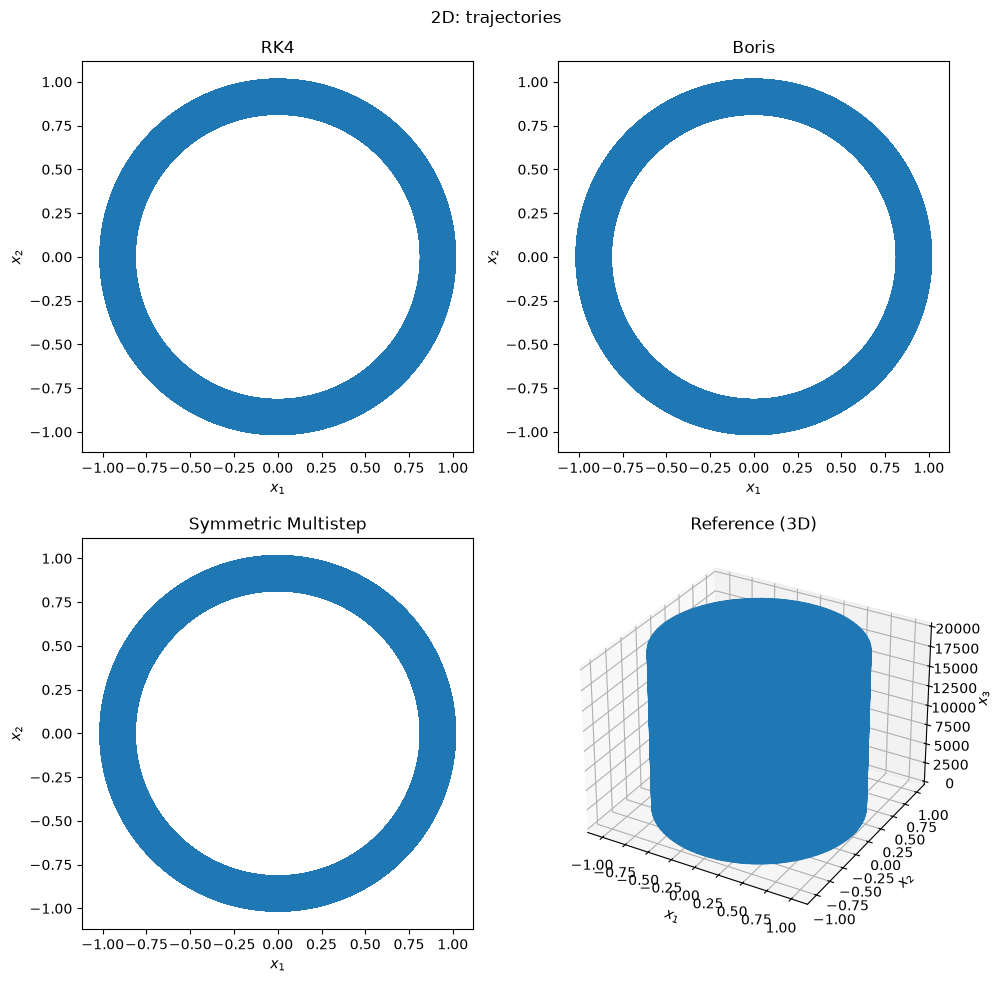

In [40]:
Sim2D.trajectPlot()

All three models find a solution with a similar shape, suggesting that our methods have been implemented correctly. Due to the long period of the simulation the solution overlaps, making it hard to get a good understanding of what is going on. We therefore reduce the time period to $10^3$ and $10^4$.

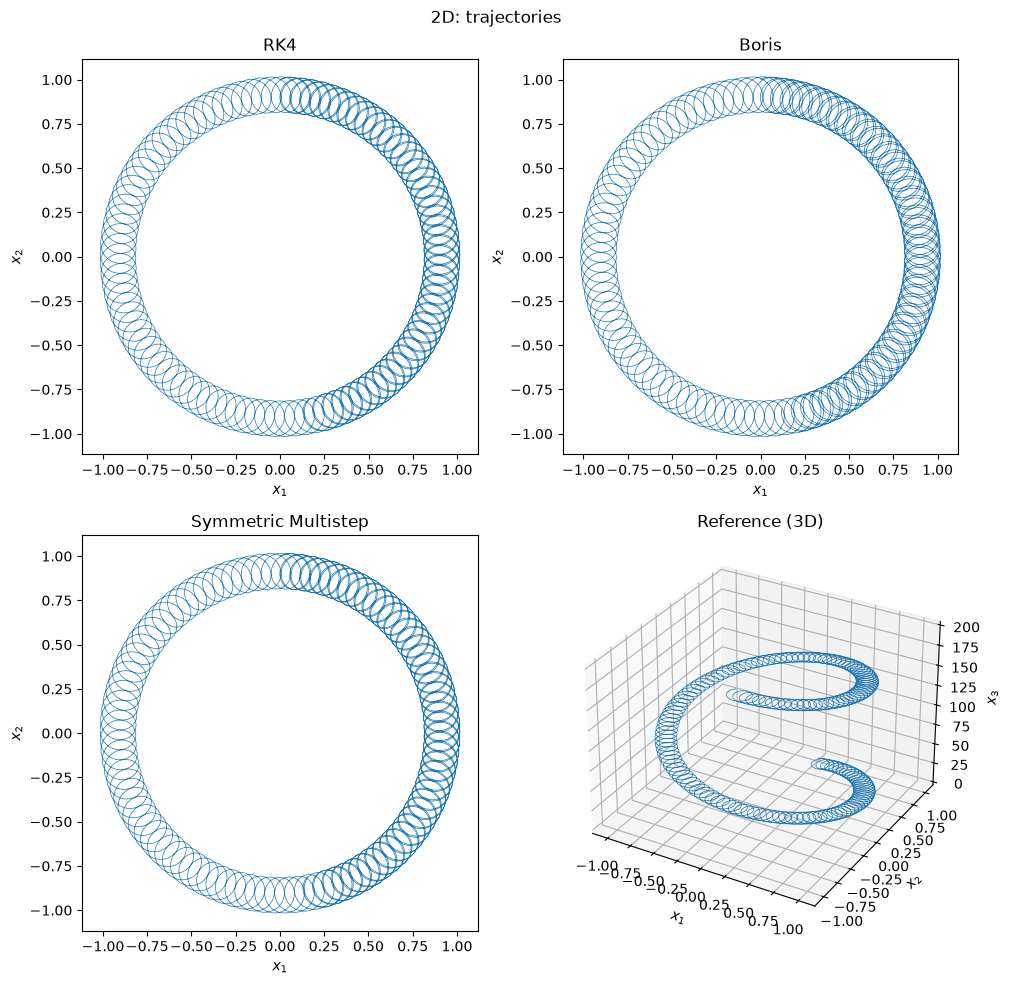

In [41]:
Sim2D.trajectPlot(cutoff=1e3)

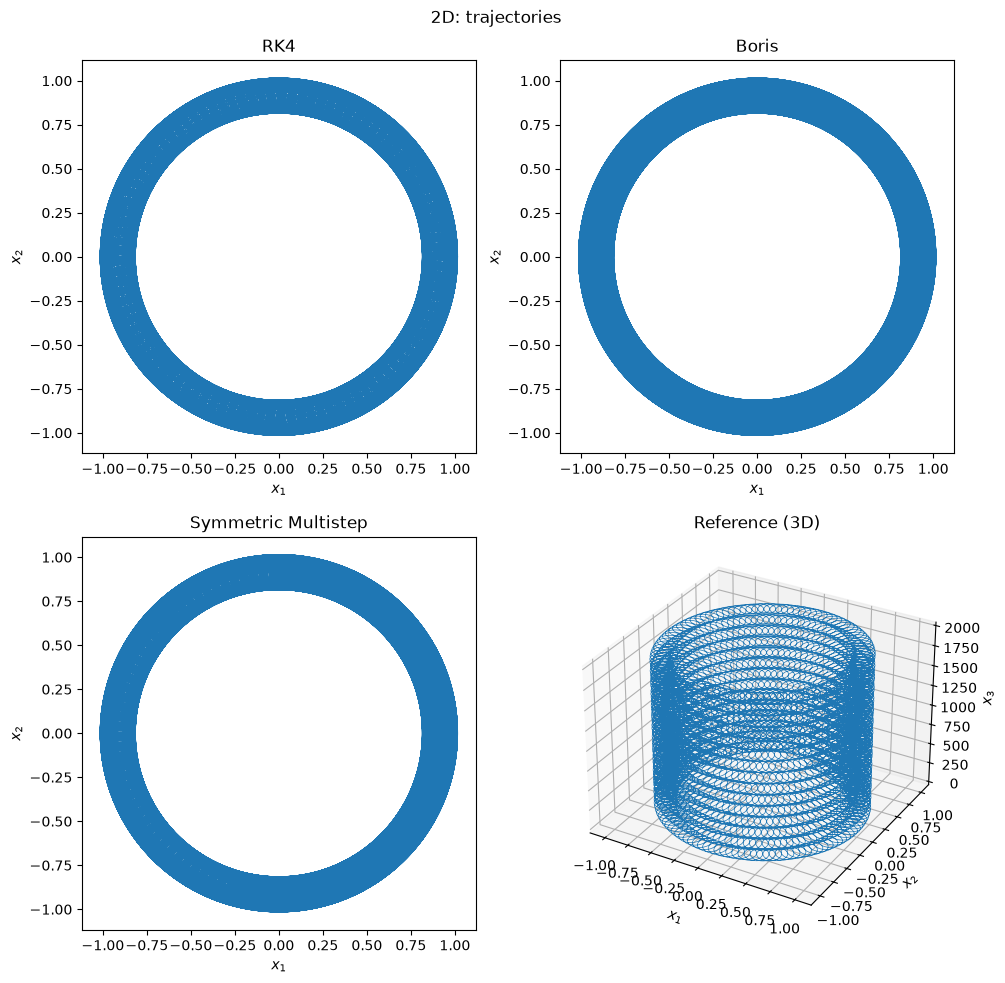

In [42]:
Sim2D.trajectPlot(cutoff=1e4)

The solution is much more appearant now. The movement is that of two different sprial shapes, one small spiral and one big spiral. In unison they have two circular motions, with a steady drift upwards. We see that this drift is approximatly constant due to the heigt being directly linearly proportional to the time, i.e. $H = 0.2\cdot T$.

The differences between the methods are more visible now. In the plot for $T=10^3$ we see some small differences in the distance in between the overlapping circles. The Boris method gives us a larger gap than the other methods. Tough what is the more correct solution is hard to know. From our theory we know that Boris is a second order method, while the others are fourth order methods. It is reasonable to assume that Boris is the method that differs the most. We will look further into this later.

## Energy Error

Before looking at an approximation of the error we look at how the different methods are stable with respect to energy. We plot the error of the energy as a function of timesteps.

C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\278273595.py:140: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
c:\Users\wibra\SKOLE\NUMMAT\TMA4215_NumericalMathematics_project_2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


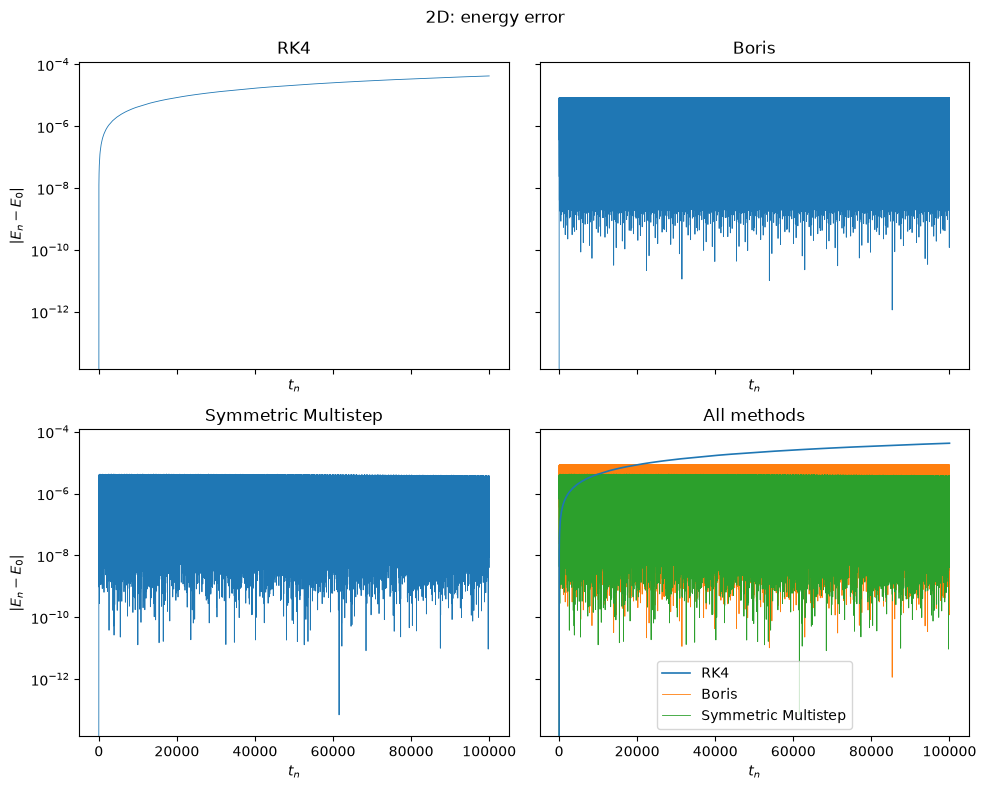

In [43]:
Sim2D.energyPlot()

`Boris` and `Symmetric multistep` are what is known as *geometric numerical integrators*, where the methods are designed in such a way that energy will be preserved over longer time intervals. While `RK4` has nothing that guarantees this. This is obvious from the above plot. The geometric numerical integrators have a strict upper bound on the energy error, while `RK4` grows with no bound. The lack of energy error bound will create some problems that we will look into later.

We are given a theorem [1, thm. 3.2] (the task says theorem 3.1, but that does not exist. We assume that this is instead what is meant) that says that a p-order s-stable symmetric multistep method  will have energy error bound $e_n = \|E(x_0,v_0)-E(x_n,v_n) \|_2 = \mathcal{O}(h^p)$ over a time period that scales by $\mathcal{O}(h^{-p-2})$. In our case $p=4$ and $h=0.1$. So the time period with stability is $C\cdot 10 ^{6}$, where $C$ is some constant. We are able to confirm that the method has an upper bound on the energy error, but we are unable to confirm the scaling parts of the theorem.

We also need to show that the symmetric multistep method is s-stable. To do this we find the roots of $\rho(\xi)$.

[1. 1. 1. 1. 1. 1. 1. 1.]
[-0.9+4.35889894e-01j -0.9-4.35889894e-01j -0.1+9.94987437e-01j
 -0.1-9.94987437e-01j  0.7+7.14142843e-01j  0.7-7.14142843e-01j
  1. +2.53026518e-09j  1. -2.53026518e-09j]


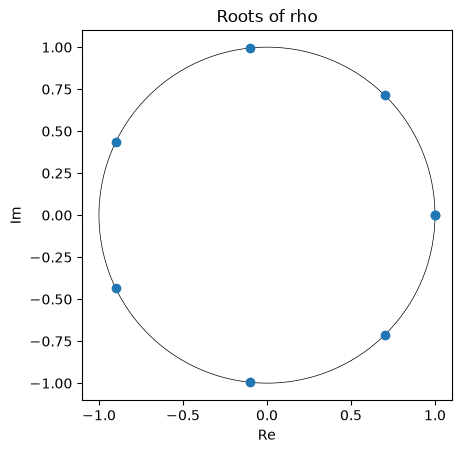

In [44]:
sstablealpha = np.array([1,-7/5,9/25,22/125,-34/125,22/125,9/25,-7/5,1])
sStableRoots = np.roots(sstablealpha)

print(np.abs(sStableRoots))
print(sStableRoots)

sstabletheta = np.linspace(0,2*np.pi,400)
plt.plot(np.cos(sstabletheta),np.sin(sstabletheta),"k",lw=0.5)
plt.plot(sStableRoots.real,sStableRoots.imag,"o")
plt.gca().set_aspect("equal")
plt.xlabel("Re")
plt.ylabel("Im")
plt.title("Roots of rho")
plt.show()

We see that there is a double root at $\xi =1$. While the rest of the roots are simple roots with modulus $1$. It is therefore an s-stable symmetric multistep method. [1, def. 3.1]

We start by checking the time period of stability. If we increase $T$ to $10^6$ maybe we will observe that this bound is ony valid up until a certain time? We plot the energy error up for the `Symmetric Multistep` below.

Symmetric Multistep done


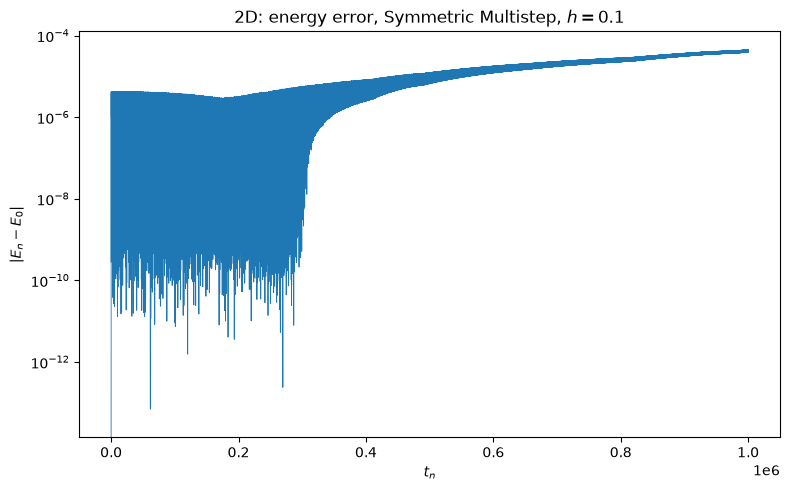

In [45]:
Sim2DBigTime = Traject("2d",h= 0.1,T=1e6,only_symmetric=True)
Sim2DBigTime.energyPlot()

The energy error bound dissappears after going roughly twice as far as it did in the last test. Suggesting that the theorem is correct in that the energy error bound is not valid for all times. In numerical mathematics, things rarely work in isolation. It could be that the energy error bound from the theorem is still in effect, but that something else is making the energy error drift.

 How this bound behaves as function of $h$ is not something we can confirm. Finding the time when the error bound is no longer valid is difficult to do precisely since it could be that the bound is invalid but the error is still under it. Also this is a long computation. Doing this several times will take too long for the purpose of this project.


We then see how the maximum energy error changes when scaling $h$. We expect it to have an lower scaling bound of $\mathcal{O}(h^4)$.

2D
  h = 0.1    max|E_n - E_0| = 4.241e-06
  h = 0.05   max|E_n - E_0| = 2.243e-07
  h = 0.025  max|E_n - E_0| = 1.283e-08
  observed orders: [4.24 4.13]


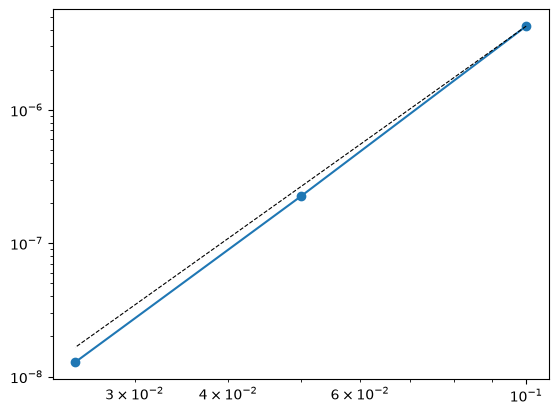

In [46]:
errs2d = energyOrderSym(create_2d(),T=1000)

We obtain the expected results as stated in the theorem. But with slightly better order. It could be that the bound given is an asymptotic bound, and we have not used small enough steps to reach this asymptotic value.

## Error

We can now look at the actual error of the trajectories. We start by cutting off the time at $T=10^3$ so that we can see which of the methods had the more correct trajectories.

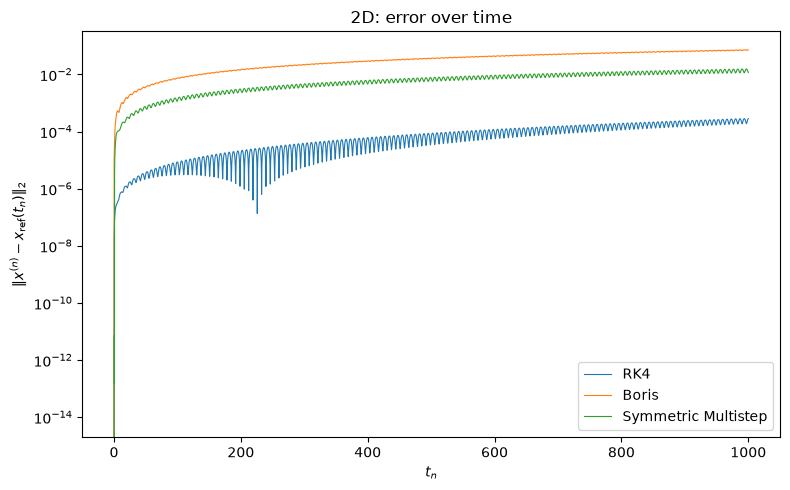

In [47]:
Sim2D.errorPlot(cutoff=1e3)

Our assumption was correct. The `Boris` method was the one with the highest error. This is not to say that the `Boris` method will be the worst method, actually we will later show otherwise. An interesting observation is how the error oscillates. Our trajectories are circular motions. It could be that there becomes an error in the phase of the small circular motion, giving us the oscillating error. Maybe this oscillation will wash out when the error becomes dominated by the error of the large cicular motion? We see what happens when we increase the time period to $T=10^5$.

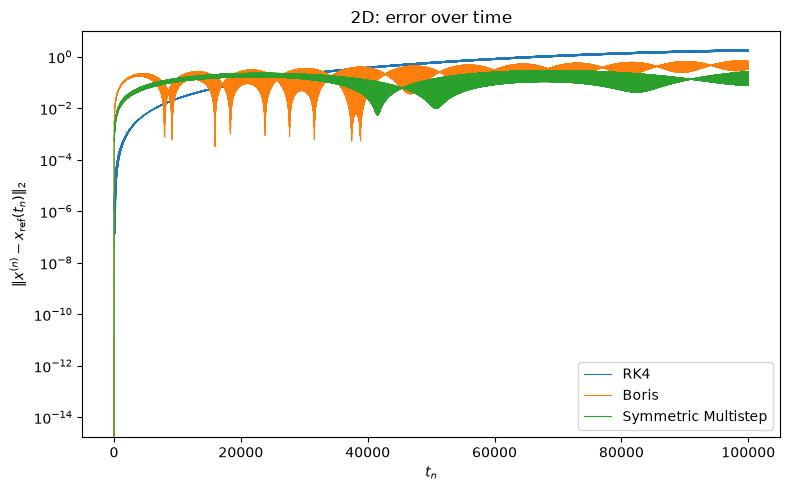

In [48]:
Sim2D.errorPlot()

From the above plot we can make a number of observations. First, the oscillation does not drown out. For `Boris` and `Symmetric Multistep` it actually increases, while `RK4` has what seems to be a constant oscillation. Second, `RK4` becomes a worse method than `Boris`, even tough it has a higher order. Third, there seems to arise a new oscillating motion for the geometric numerical integrators. All of these observations can be explained by the conservation of energy.

We start by discussing the error of `RK4`. For the first $30.000$ steps it is the best method, but after this it starts drifting away from the other methods. This is due to a lack of conservation of energy. By looking at the plot of the energy error, we see that it is at around this time the energy error for `RK4` becomes larger than for the other methods. But `RK4` should be method of higher order. Why is it worse? This is because `RK4` is of a higher order with respect to $h$, but not with respect for $T$. We can think of it like this $\mathcal{O}(h^p) = C(T)h^p$. A higher order says that it scales better with smaller $h$, but says nothing about how $C(T)$ behaves. The lack of energy conservation makes $C(T)$ scale faster for `RK4` than `Boris`.

The geometric numerical integrators now work as big oscillators. The energy error plots seem to vary in thicknes, but this actually just the small oscillation being scaled. What we observe is similar to an interference pattern from the superposition of two oscillating functions, where the thick error plot functions as a carrier wave. We know that the trajectory is two circular motions. It could be that we get a phase shift for both the small and big circular motion. Together they create oscillating error we observe. This would also explain why `Boris` oscillates with a higher frequency than `Symmetric Multistep`. `Boris` is a less precise method, so the phases shift faster thereby creating a higher frequency.

This oscillating motion is not something we observe for `RK4`. This suggests that `RK4` has no large oscillating sources of errors. We know that the energy error for `RK4` does not follow an osciallting motion, and has a similar shape. It could very well be that the reason we do not see an oscillating error is due to the error being domimated by an non-oscillating energy error.

Note that it could be interesting to look further into the oscillating properties. But this is outside the scope of this task.

# Tokamak

We then do the same for the Tokamak system

## Trajectories

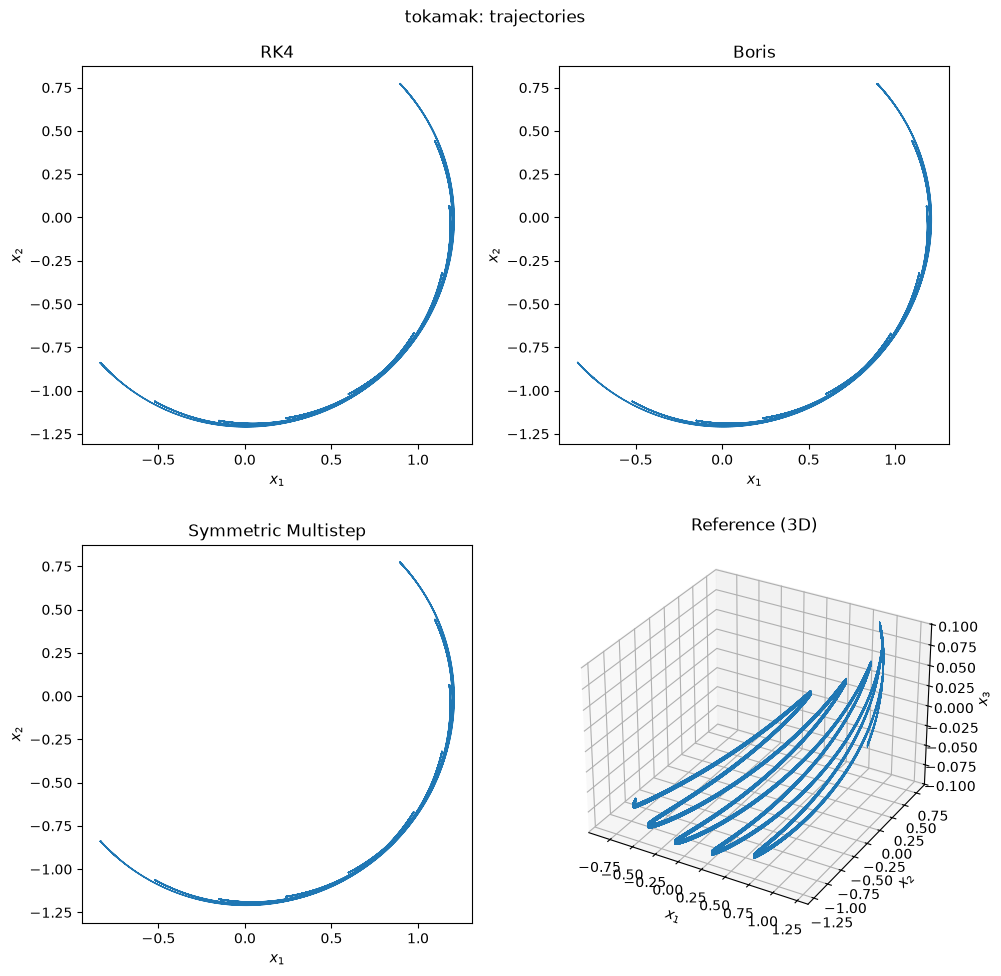

In [49]:
simTokamak.trajectPlot()

There seems to be very little difference between the methods from the plots alone. There is again a circular motion. So we assume that we will observe similar oscillations for the error plots.

## Banana Orbit

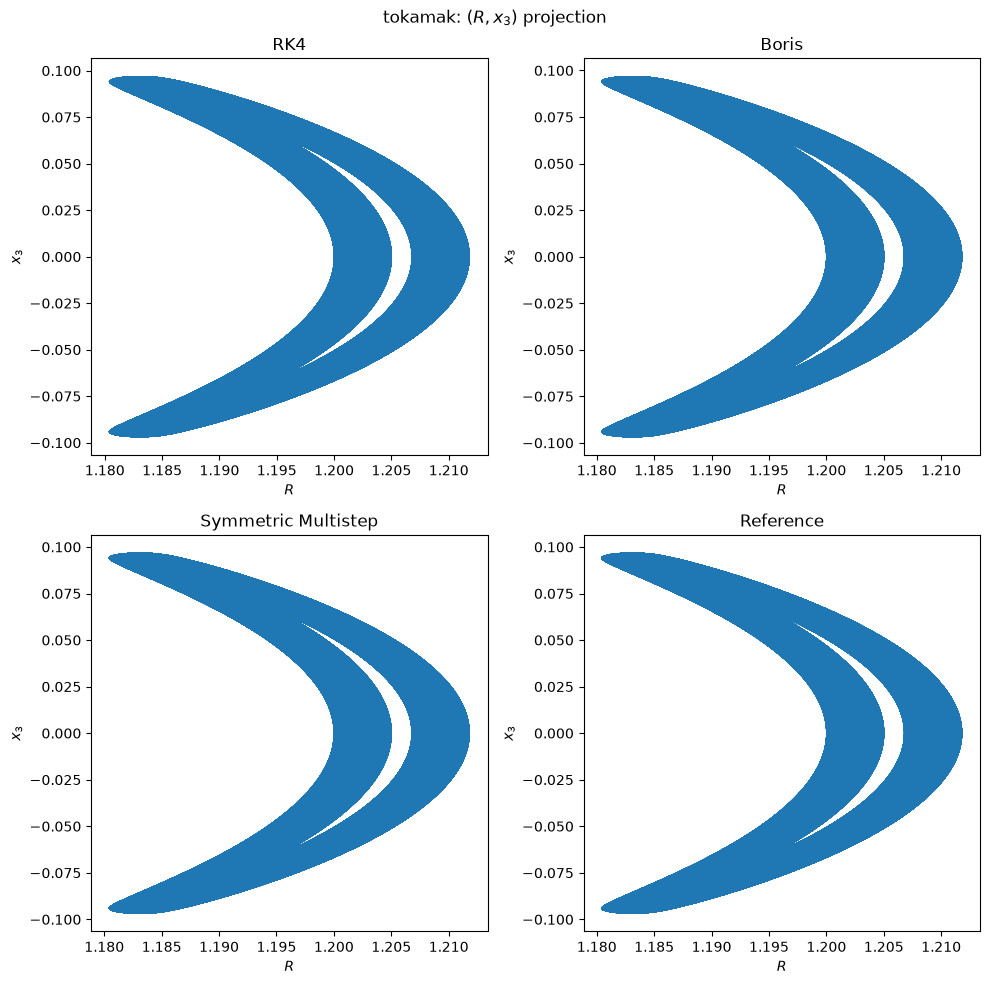

In [50]:
simTokamak.bananaPlot()

We get the expected Banana orbits. This is mainly a qualitive correctness test for the implementations for our methods. The banana orbit is the result of the physical rules. So it is more of a check for numerical geometric integrators. We expect that for higer values of $T$ we whould see a drift for `RK4`.

## Energy Error

Again we start by looking at the enegy errors.

C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\278273595.py:140: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()


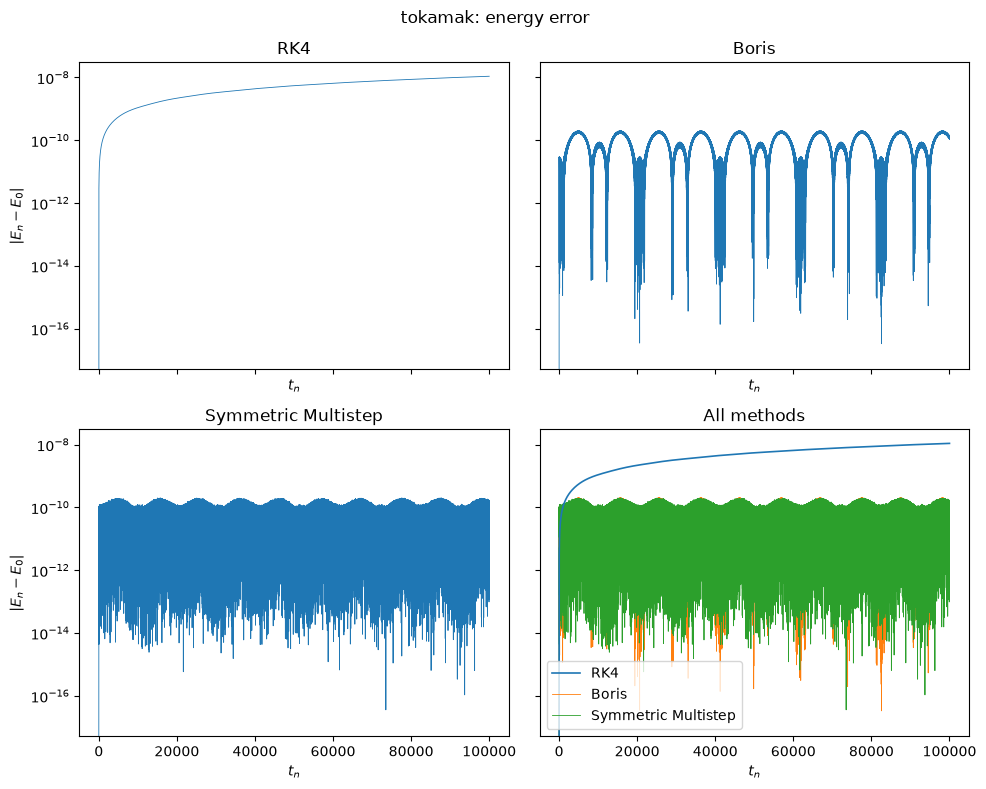

In [51]:
simTokamak.energyPlot()

We again observe simmilar results. For the geometrical numerical integrators the energy error has a constant bound, while `RK4` drifts away. What is different in this case is that there seems to be some oscillations in the energy error as well. This can be explained by the lack of high frequency oscillations. We assume that there was oscillation in the energy error for the 2D system as well. Only that the frequency was so high that it looked like just noise.

The difference between how `Boris` and `Symmetric Multistep` behaves suggest that they use different methods to conserve energy.

Here we also see that we are in the time region of energy conservation for `Symmetric Multistep`. We repeat the experiment by increasing $T$ to $10^6$, predicting that the error will go beyond its bound after enough timesteps.

C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\1032597241.py:60: RuntimeWarning: overflow encountered in scalar power
  -0.5 * (x3 * np.arctan2(x2, x1) + np.log(rho**2)),
C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\1064482452.py:18: RuntimeWarning: invalid value encountered in subtract
  return DA(x[j]).T@v -Acd -DU(x[j]),v # return the actual value for F_j
C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\1032597241.py:59: RuntimeWarning: invalid value encountered in scalar add
  0.5 * (x1 - np.log(rho + x1)),
C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\1032597241.py:51: RuntimeWarning: overflow encountered in scalar power
  [(x2*x3 - 2*x1)/(2*rho**2), -(x1*x3 + 2*x2)/(2*rho**2), -0.5*np.arctan2(x2, x1)],
C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\1064482452.py:18: RuntimeWarning: invalid value encountered in matmul
  return DA(x[j]).T@v -Acd -DU(x[j]),v # return the actual value for F_j
C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\1032597241.py:50: RuntimeW

Symmetric Multistep done


C:\Users\wibra\AppData\Local\Temp\ipykernel_27520\48899629.py:27: RuntimeWarning: overflow encountered in square
  kinetic = 0.5 * np.sum(V**2, axis=1) # The kinetic part


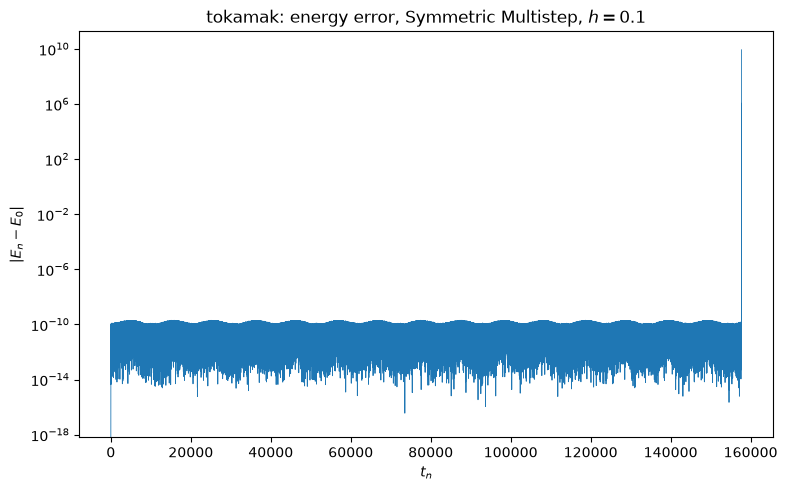

In [ ]:
SimTotakLongTime = Traject("tokamak",h= 0.1,T=1e6,only_symmetric=True)
SimTotakLongTime.energyPlot()

This result is surprising. We observe the same bound for the energy error, but instead of a steady drift in the energy error the solution blows up. It could be that what keeps the energy error low is also the same part that makes the method stable, so once that no longer works the method diverges. Another theory could be that the solution reaches some sort of instable area of the system? Maybe our equations only work for a certain area, and once we get outside the area the equations break down and we get a blow up? We are already outside of what the project asks of us, so we decide that a deeper dive into this is outside the scope of this project.

It is worth to note that the blow up happens around where Yang He et. al [2] stop their simulations. We could not find why they stopped at this time. So maybe it is by chance? Maybe they did this since going further than this causes a breakdown in the system?

We also check for the order of the maximum energy error.

tokamak
  h = 0.1    max|E_n - E_0| = 1.933e-10
  h = 0.05   max|E_n - E_0| = 8.150e-12
  h = 0.025  max|E_n - E_0| = 4.068e-13
  observed orders: [4.57 4.32]


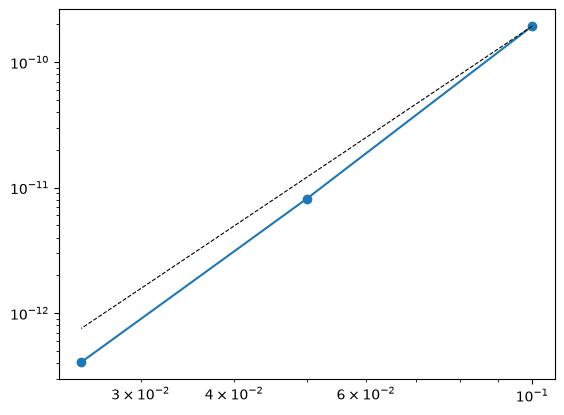

In [53]:
errsTok = energyOrderSym(create_tokamak(),T=10000)

We again see the energy error scaling better than what the theorem says. This again could come from the theorem giving an asymptotic bound that we have not reached. The order is better here than for the 2d system. From previous discussion it looks like the energy in the tokamak system is easier to get right. So maybe there is something in the system that gives us a better bound?

## Error

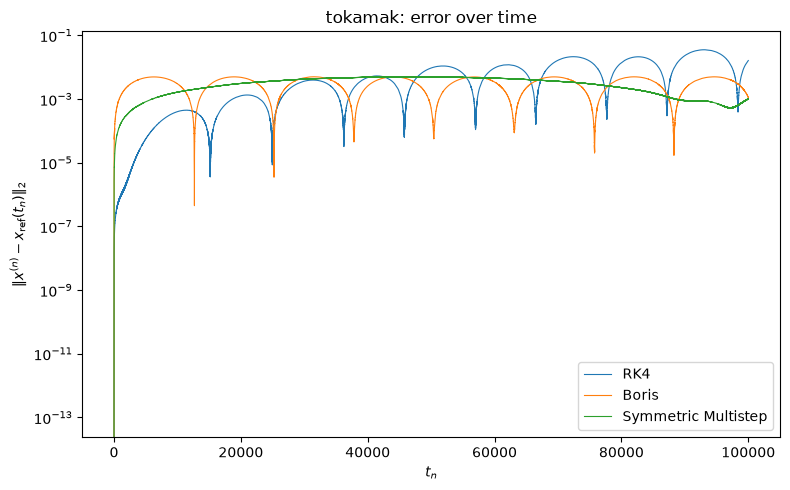

In [54]:
simTokamak.errorPlot()

The error is also quite different at first glance. We start by discussing the geometric numerical integrators. At first it looks like `Symmetric Multistep` no longer oscillates as for the 2D system, while `Boris` keeps the oscillation. But in actuality it seems like the `Symmetric Multistep` method keeps the oscillating patter, but that the period is so long that we only see one oscillation. If we look at the end of the plot we see that the error dips and starts rising again. Starting a new period. We see much slower oscillating patterns because the trajectories have slower oscillation. In this system we also have only one oscillating motion instead of two. So we do not see the same interference pattern as before.

The biggest difference comes from `RK4`, which now has an obvious oscillating pattern. We theorized that for the 2D systems the main sources for error for `RK4` were non-oscillating, making the error non-oscillating. We suggested that the main source of error came from the energy error. For the Tokamak system the energy errors are lower by several orders of magnitude. So maybe the reason we see an oscillating error for `RK4` comes from that the main source of error is a deviation from the banana orbit instead of an error in the energy?

## Task B: Order verification and work–precision diagrams

### Setup

For both systems we run all three methods with the step sizes

$$h_i = \frac{h}{2^i}, \qquad i = 0, 1, 2, \qquad h = 0.1,$$

that is $h_i = 0.1,\ 0.05,\ 0.025$, up to the fixed end time $T = 10^3$ (the task allows a shorter interval than in Task A). The global error is measured at the end time,

$$e_i^{\text{method}} = \big\| x^{\text{method}}_{(N_i)} - x^{\text{ref}}(T) \big\|_2, \qquad T = h_i N_i .$$

The reference solution $x^{\text{ref}}(T)$ is computed with `solve_ivp` on system (1), using `DOP853` (an adaptive Runge–Kutta method of order 8) with `rtol = atol = 1e-12`. It is computed once per system and used for every method, since $T$ is the same in all runs. The runtime $\tau_i$ of each method is measured with `time.perf_counter()` and includes everything the method does, also the start-up (the half step backwards for Boris and the eight starting values for the multistep method). We repeat each run 3 times and use the fastest of them to limit the effect another process on the machine may have on the time. (The runs are deterministic so other processes can only make the runs slower, therefor we use the fastest one.)


**Why a log–log plot shows the order.** If $e \approx C h^p$, then $\log e = \log C + p \log h$, a straight line with slope $p$. When the step size is halved, the error is divided by $2^p$, so the observed order can be estimated as

$$p_i \approx \log_2 \frac{e_{i-1}}{e_i}.$$

The expected orders are $p = 4$ for RK4, $p = 2$ for Boris and $p = 4$ for the symmetric multistep method.

In [55]:
def task5B(methods, system, T=1e3, h0=0.1):
    # Order of convergence and work-precision for a list of methods on one system ("2d" or "tokamak").
    # All methods are called as method(sys, h, T) and return (X, V, times, name),
    # so the function does not need to know which method it runs.
    # sys is a dict with the functions B, A, DA, U, DU, the initial values x0, v0 and the name ("2D"/"tokamak").
    # It is passed on to the methods, and sys['name'] is used in the printouts, titles and file names below
    sys = create_2d() if system == "2d" else create_tokamak()
    h = h0 / 2**np.arange(3)                 # h_i = h0 / 2^i: 0.1, 0.05, 0.025

    # Reference solution with solve_ivp (DOP853, rtol = atol = 1e-12). We only need the end point x_ref(T),
    # and T is the same for all runs, so it is computed once and reused for all methods and step sizes.
    XRef = findXref(sys,np.array([0.0,T]))
    print("XRef Done")

    # Left: error against step size (order). Right: runtime against error (work-precision).
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    results = {}                             # observed orders per method, returned for the table
    for method in methods:
        err = np.zeros(3)
        tau = np.zeros(3)
        for i, hi in enumerate(h):
            # The runtime is measured around the whole call, so the start-up (the half step backwards
            # for Boris, the starting values for the multistep method) is included.
            # Each run is repeated 3 times and tau is the fastest one. Noise (other programs, background
            # processes) can only make a run slower, never faster, so the minimum is the best estimate of the cost,
            # this was implemented due to some inconsistentencis in the results
            runtimes = []
            for _ in range(3):
                start = perf_counter()
                X, V, times, name = method(sys, hi, T)
                runtimes.append(perf_counter() - start)
            tau[i] = min(runtimes)
            # Global error at the end point: e_i = ||x_(N_i) - x_ref(T)||_2
            err[i] = np.linalg.norm(X[-1] - XRef[-1])
            print(f"{sys['name']:8s} {name:20s} h = {hi:.4f}: e = {err[i]:.3e}, tau = {tau[i]:.2f} s")

        # Observed order p_i = log2(e_{i-1} / e_i), since h is halved for each i:
        # e ≈ C h^p gives e_{i-1} / e_i ≈ 2^p
        orders = np.log2(err[:-1] / err[1:])
        results[name] = orders
        print(f"{sys['name']:8s} {name:20s} observed order: " + ", ".join(f"{p:.2f}" for p in orders))

        # Log-log: e ≈ C h^p becomes a straight line with slope p
        axs[0].loglog(h, err, "o-", label=name)
        # Work-precision: tau ∝ e^(-1/p), so slope -1/p
        axs[1].loglog(err, tau, "o-", label=name)


    # Reference lines in black, so they are not confused with the methods.
    # They start at the first error of the last method in the list, and are only used to compare slopes.
    for p, style in ((2, "k--"), (4, "k:")):
        axs[0].loglog(h, err[0] * (h / h[0])**p, style, label=f"$h^{p}$")

    axs[0].set_xlabel("$h_i$"); axs[0].set_ylabel("$e_i$")
    axs[0].set_title(f"{sys['name']}: order verification")
    axs[1].set_xlabel("$e_i$"); axs[1].set_ylabel(r"$\tau_i$ [s]")
    axs[1].set_title(f"{sys['name']}: work–precision")
    for ax in axs:
        ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)   # close the figure so the next plot is not drawn on top of it
    return results


XRef Done
2D       RK4                  h = 0.1000: e = 2.837e-04, tau = 1.52 s
2D       RK4                  h = 0.0500: e = 1.081e-05, tau = 3.07 s
2D       RK4                  h = 0.0250: e = 4.582e-07, tau = 6.01 s
2D       RK4                  observed order: 4.71, 4.56
2D       Boris                h = 0.1000: e = 7.240e-02, tau = 0.67 s
2D       Boris                h = 0.0500: e = 1.836e-02, tau = 1.34 s
2D       Boris                h = 0.0250: e = 4.594e-03, tau = 2.66 s
2D       Boris                observed order: 1.98, 2.00
2D       Symmetric Multistep  h = 0.1000: e = 1.171e-02, tau = 0.43 s
2D       Symmetric Multistep  h = 0.0500: e = 6.987e-04, tau = 0.87 s
2D       Symmetric Multistep  h = 0.0250: e = 4.278e-05, tau = 1.72 s
2D       Symmetric Multistep  observed order: 4.07, 4.03


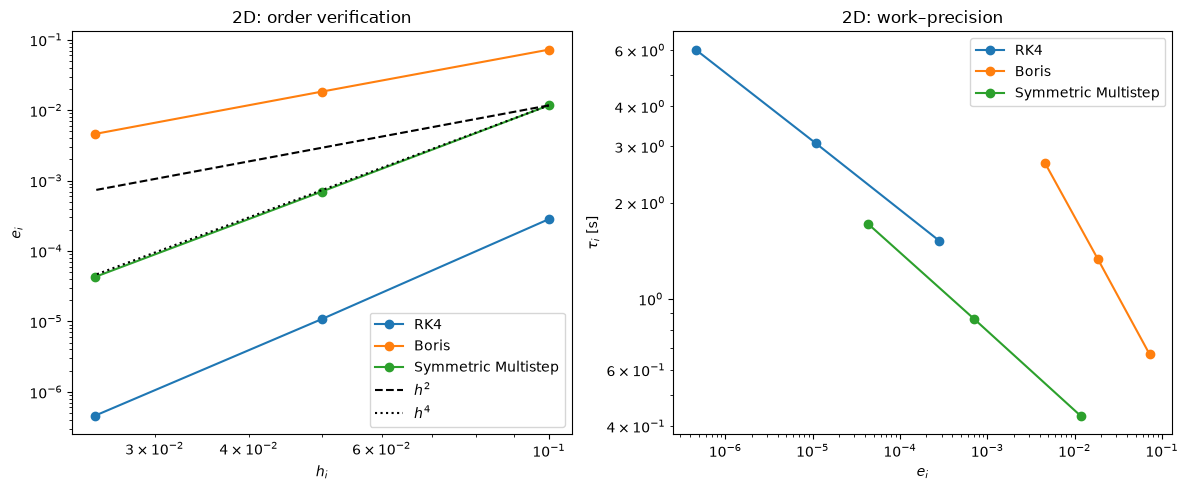

In [56]:
methods = [RK4, boris, symmetricMultistep]
orders2D = task5B(methods, "2d")

XRef Done
tokamak  RK4                  h = 0.1000: e = 8.174e-07, tau = 1.53 s
tokamak  RK4                  h = 0.0500: e = 5.200e-08, tau = 2.97 s
tokamak  RK4                  h = 0.0250: e = 3.189e-09, tau = 6.12 s
tokamak  RK4                  observed order: 3.97, 4.03
tokamak  Boris                h = 0.1000: e = 1.214e-03, tau = 0.65 s
tokamak  Boris                h = 0.0500: e = 3.063e-04, tau = 1.27 s
tokamak  Boris                h = 0.0250: e = 7.662e-05, tau = 2.55 s
tokamak  Boris                observed order: 1.99, 2.00
tokamak  Symmetric Multistep  h = 0.1000: e = 1.610e-04, tau = 0.44 s
tokamak  Symmetric Multistep  h = 0.0500: e = 9.957e-06, tau = 0.90 s
tokamak  Symmetric Multistep  h = 0.0250: e = 6.206e-07, tau = 1.77 s
tokamak  Symmetric Multistep  observed order: 4.01, 4.00


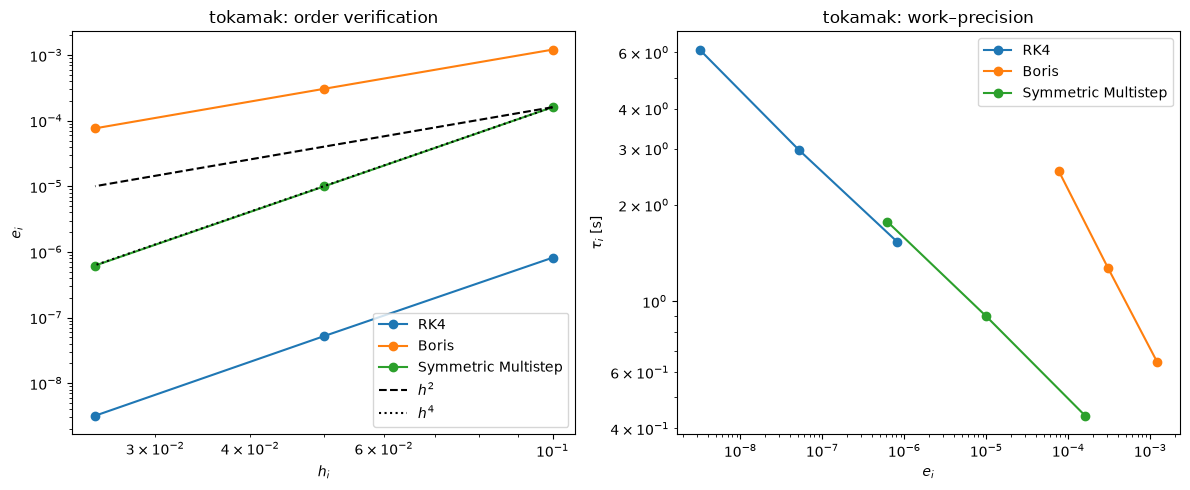

In [57]:
ordersTokamak = task5B(methods, "tokamak")

### Results


Observed orders $p_1, p_2$ (from halving $h$ from 0.1 to 0.05, and from 0.05 to 0.025):


In [58]:
# Observed orders p_1, p_2 from the runs above, collected in a table
expected = {"RK4": 4, "Boris": 2, "Symmetric Multistep": 4}
rows = ["| Method | 2D | Tokamak | Expected |", "|---|---|---|---|"]
for name in orders2D:
    p2D = ", ".join(f"{p:.2f}" for p in orders2D[name])
    pTok = ", ".join(f"{p:.2f}" for p in ordersTokamak[name])
    rows.append(f"| {name} | {p2D} | {pTok} | {expected[name]} |")
display(Markdown("\n".join(rows)))

| Method | 2D | Tokamak | Expected |
|---|---|---|---|
| RK4 | 4.71, 4.56 | 3.97, 4.03 | 4 |
| Boris | 1.98, 2.00 | 1.99, 2.00 | 2 |
| Symmetric Multistep | 4.07, 4.03 | 4.01, 4.00 | 4 |

### Comments

#### Order of convergence

We managed to verify the expected orders for all three methods on both systems. In the log–log plots all curves are straight lines, Boris is parallel to the $h^2$ reference line, and RK4 and the symmetric multistep method are parallel to the $h^4$ line. The observed orders in the table are very close to 2 and 4.

The only deviation is RK4 on the 2D system, where the observed order is about 4.6 instead of 4. We think this is because the step sizes are not yet small enough for the error to be fully asymptotic: the error is $e = C h^4 + \mathcal{O}(h^5)$, and for $h = 0.1$ the higher-order terms still contribute. On the Tokamak system, RK4 gives 3.97 and 4.03. For a few more halvings of $h$ we would expect the 2D value to approach 4 as well.

We also checked that the reference solution is accurate enough. The smallest error we measure is $3.2 \cdot 10^{-9}$ (RK4 on the Tokamak system with $h = 0.025$), which is far above the tolerance $10^{-12}$ of the reference solution. If the reference solution were too inaccurate, the smallest errors would flatten out in the order plot. They do not, and RK4 keeps order 4 down to this error, so the reference solution does not affect the results.

#### Accuracy for a fixed step size

For the same step size, RK4 is clearly the most accurate method, followed by the symmetric multistep method and then Boris. With $h = 0.1$, the error of RK4 is $2.8 \cdot 10^{-4}$ against $1.2 \cdot 10^{-2}$ for the multistep method on the 2D system , and $8.2 \cdot 10^{-7}$ against $1.6 \cdot 10^{-4}$ on the Tokamak system, even though both methods have order 4. The difference is in the error constant $C$. Boris has order 2 and is therefore several orders of magnitude less accurate than the two fourth-order methods.

#### Work–precision: which method is most efficient?

Efficiency is not the runtime alone, but how much runtime a method needs to reach a given error. In the work–precision diagram the most efficient method is therefore the one whose curve lies lowest for a given error on the $x$-axis. These comparisons are also only for our implementations of the methods. We only update the nedded parameters for each computation, so the time spent should be close to optimal, altough noice from other processes on the machine may disturb runtimes that are this small. 

The symmetric multistep method looks to be the most efficient, altough just barely. Its most prescise run achives a slightly lower computation time and error than the fastest RK4 run for both approximations, and its curve seems to stay lower. This makes sense considering that both methods curves should be parallel with a downward slope $ - 1/4 $ in the log plot, since they are fourth order methods. So we can expect The symmetric multistep method to achive lower computation time for the same error, given that it beats out RK4 for the one error.  
The Boris method is much less efficient in the whole range we measured, its curve lies above the others everywhere. Its slope is $ - 1/2 $, instead of $ - 1/4 $, so the gap will also grow larger as the error tolerance decreases. 

The efficiency results were mostly as expected: higher order pays off when high accuracy is needed, and a method with fewer function evaluations per step is cheaper. More surprising was how small the error constant of RK4 is compared to the multistep method, which makes RK4 almost as efficient as the multistep method on the Tokamak system even though it requires more computations. 

### Conclusion

We verified the expected orders of convergence for all three methods on both systems: order 2 for Boris and order 4 for RK4 and the symmetric multistep method. The only deviation was RK4 on the 2D system, where the observed order of about 4.6 indicates that the error is not fully asymptotic for these step sizes.

For a fixed step size RK4 is the most accurate method, but it is also the most expensive per step. When accuracy and runtime are considered together, the symmetric multistep method is the most efficient, with RK4 close behind, especially on the Tokamak system. Boris is the least efficient in the whole range we measured. The work–precision curves have slopes $-1/p$ predicted by the order $ p $, so the advantage of the fourth-order methods over Boris grows as the error tolerance decreases.

These results only concern accuracy at a fixed and fairly short end time $T = 10^3$. They do not say anything about the long-time behaviour, such as energy conservation, which we look at in task A.

---

# Exploratory exercise

# Showing convergence of the symmetric linear multistep method of order 4 analytically; Dahlquist's Theorem

We have shown numerically that the symmetric multistep method of order 4 is s-stable, and we have plotted the roots on the unit circle in the complex plane. Although, as mathematicians - but first and foremost as problem solvers - we should always keep a critical eye. Naturally, an interesting question to ask is ***why*** the method is convergent. This can be proven through Dahlquist's Theorem, which states:

$$
\text{A linear multistep method is convergent} \Longleftrightarrow \text{The method is zero-stable and consistent}
$$

This means we need to show both zero-stablity and consistency of the method. 

**Zero-stability** means that small perturbations, such as rounding errors or errors in the starting values, are not amplified as the number of steps grows. It is a property of the method in the limit $h\to0$, where the right-hand side vanishes and only the difference equation $\sum_ia_ix_{m+i}=0$ remains. 

**Consistency** means that the method approximates the differential equation it is meant to solve. Inserting the exact solution into the method leaves a remainder, the defect $d_m$, and the method is consistent if $d_m/h^2\to0$ as $h\to0$.


For the proof, we will cite the pre-estalished equations given in [1], as the project description cites its equations from this same source. 

### **Background:** 
The equation of motion is [1, eq. (1.1)]

$$\ddot x=\dot x\times B(x)-\nabla U(x),$$

where $\dot x\times B(x)$ is the magnetic force and $-\nabla U(x)$ the electric (conservative) force. With $B=\nabla\times A$, the magnetic force can be rewritten as $A'(x)^\top\dot x-\tfrac{d}{dt}A(x)$ [1, eq. (1.2)]. The method discretises this form [1, eq. (2.1)]:

$$\sum_{i=-4}^{4}\alpha_i x_{n+i}=h^2\sum_{i=-1}^{1}\beta_i\Big[A'(x_{n+i})^\top\tfrac1h\sum_{j=-2}^{2}\delta_jx_{n+i+j}-\tfrac1h\sum_{j=-2}^{2}\delta_jA(x_{n+i+j})-\nabla U(x_{n+i})\Big].$$



## **Zero-stability**
### **Claim:** The symmetric multistep method of order 4 with coefficients $(\alpha_{-4},\dots,\alpha_4)=\left(1,-\tfrac75,\tfrac9{25},\tfrac{22}{125},-\tfrac{34}{125},\tfrac{22}{125},\tfrac9{25},-\tfrac75,1\right)$ is zero-stable.

### **Proof:**

We have that

$$\sum_{j=-4}^{4}\alpha_jx_{n+j}=h^2(\beta_1F_{n-1}+\beta_0F_n+\beta_1F_{n+1}),$$

where $F_n$ is the approximation of the right-hand side of the differential equation at $x_n$, including the magnetic terms [1, Remark 2.1]. To match the standard form of a $k$-step method, we **shift the index**, $m=n-4$, so that the nine points $x_{n-4},\dots,x_{n+4}$ become $x_m,\dots,x_{m+8}$, and rename the coefficients $a_i=\alpha_{i-4}$ for $i=0,\dots,8$:

$$(a_0,\dots,a_8)=\left(1,-\tfrac75,\tfrac9{25},\tfrac{22}{125},-\tfrac{34}{125},\tfrac{22}{125},\tfrac9{25},-\tfrac75,1\right).$$

The left-hand side is then $\sum_{i=0}^{8}a_ix_{m+i}$, so this is an 8-step method.

Zero-stability concerns the limit $h\to0$. Since the right-hand side carries the factor $h^2$, it vanishes in this limit, and the method reduces to the difference equation

$$
\sum_{i=0}^{8}a_ix_{m+i}=0
$$

with characteristic polynomial

$$
\rho(\zeta)=\sum_{i=0}^{8}a_i\zeta^i,
$$

of degree 8 with no negative powers of $\zeta$. Zero-stability of the method is therefore determined by the eight roots of $\rho$ alone, independently of $F_n$ and the $\beta_i$ [1, Remark 2.1]. In finding these roots, it helps to use the symmetry of the method. We notice that $a_i = a_{8-i}$ and $\rho(0) = a_0 = 1 \neq 0$, so $\zeta = 0$ is not a root. Therefore, we can write out the degree-8 polynomial as such:

$$
\rho(\zeta)=a_0+a_1\zeta+a_2\zeta^2+a_3\zeta^3+a_4\zeta^4+a_5\zeta^5+a_6\zeta^6+a_7\zeta^7+a_8\zeta^8. 
$$

#### **Trick:** simplifying the problem by dividing by $\zeta^4$ and using substitution(s) of variables. 

Since we are after the roots of $\rho(\zeta)$ and $\zeta\neq0$, it is safe to divide the equation by $\zeta^4$ and group terms by the symmetry of the coefficients

$$
\frac{\rho(\zeta)}{\zeta^4} = a_4 + a_5(\zeta+\zeta^{-1}) + a_6(\zeta^2+\zeta^{-2}) + a_7(\zeta^3+\zeta^{-3})+a_8(\zeta^4+\zeta^{-4})
$$
and then simply insert the coefficients
$$
\frac{\rho(\zeta)}{\zeta^4}=-\frac{34}{125}+\frac{22}{125}(\zeta+\zeta^{-1})+\frac{9}{25}(\zeta^2+\zeta^{-2})-\frac{7}{5}(\zeta^3+\zeta^{-3})+(\zeta^4+\zeta^{-4}).
$$

Now, we can use a subsitution to turn our degree-8 problem to a degree-4 problem. This allows us to solve the problem by finding the roots of a simpler equation. After this, we just revert the substitution to find the roots of our original polynomial. Define $u:=\zeta+\zeta^{-1}$. Expressing $\zeta^j+\zeta^{-j}$ for $j=1,2,3,4$ using $u$, can be done by raising $u$ to the power of $j$:

$j=1:$
$$\underline{u^1=u=\zeta+\zeta^{-1}}$$
$j=2:$
$$u^2=(\zeta+\zeta^{-1})(\zeta+\zeta^{-1})=\zeta^2+2+\zeta^{-2} \Longleftrightarrow \underline{\zeta^2+\zeta^{-2}=u^2-2}.$$
$j=3$ (using the trick of multiplying the previous result by $u$):
$$u(\zeta^2+\zeta^{-2})=(\zeta+\zeta^{-1})(\zeta^2+\zeta^{-2})=\zeta^3+\zeta^{-3}+\zeta+\zeta^{-1} \Longleftrightarrow \underline{\zeta^3+\zeta^{-3}}=u(u^2-2)-u=\underline{u^3-3u}.$$
$j=4$ (using the same trick):
$$u(\zeta^3+\zeta^{-3})=(\zeta+\zeta^{-1})(\zeta^3+\zeta^{-3})=\zeta^4+\zeta^{-4}+\zeta^2+\zeta^{-2} \Longleftrightarrow \underline{\zeta^4+\zeta^{-4}}=u(u^3-3u)-(u^2-2)=\underline{u^4-4u^2+2}.$$

Finally we insert the $u$-substitution into the equation and multiply out the constants:

$$\frac{\rho(\zeta)}{\zeta^4}=q(u)=u^4-\frac75u^3-\frac{91}{25}u^2+\frac{547}{125}u+\frac{126}{125},$$

and call this right hand side $q(u)$. Four roots are found when $q(u)=0$, so let us try to factorize the equation. In advance, from the theorem of order conditions, we know that the coefficients sum to zero: 
$$\sum_{i=0}^{8}a_i=2\left(1-\frac75+\frac9{25}+\frac{22}{125}\right)-\frac{34}{125}=2\cdot\frac{17}{125}-\frac{34}{125}=0.$$

From this, it can easily be seen that for $\zeta=1 \Rightarrow \rho(1)=0 \Rightarrow u=1+1=2 \Rightarrow q(2)=0$. So, we can pull out $(u-2)$ from the equation using polynomial divison:

$$q(u)=(u-2)\left(u^3+\frac35u^2-\frac{61}{25}u-\frac{63}{125}\right).$$

We notice that the denominators in the cubic equation $u^3+\frac35u^2-\frac{61}{25}u-\frac{63}{125}$ are all products of $5$ ($5^2=25,\ 5^3=125$). Therefore, let us use another subsitution. Define $v:=5u$. Multiplying out the cubic equation with this substitution out gives us

$$\left(\frac v5\right)^3+\frac35\left(\frac v5\right)^2-\frac{61}{25}\cdot\frac v5-\frac{63}{125}=\frac{v^3+3v^2-61v-63}{125} \Longrightarrow v^3+3v^2-61v-63 = 0.$$
For a polynomial with integer coefficients and leading coefficient 1, any rational root is an integer dividing the constant term; in this case $-63$. The candidates are $\pm1,\pm3,\pm7,\pm9,\pm21,\pm63$. Let us start with $v=\pm1$:

$$v=1: 1+3-61-63=-120\neq0, \qquad v=-1: -1+3+61-63=0$$

so $v=-1$ is a root and $(v+1)$ is a factor. Dividing it out leaves a quadratic, which factors directly (using the integer method or the "abc/quadratic-formula"):

$$v^3+3v^2-61v-63=(v+1)(v^2+2v-63)=(v+1)(v+9)(v-7).$$

The roots are $v=-1$, $v=-9$ and $v=7$. Since $u=v/5$, the roots of the cubic are $u=-\frac15$, $u=-\frac95$ and $u=\frac75$. Together with $u=2$ this gives

$$q(u)=(u-2)\left(u-\frac75\right)\left(u+\frac15\right)\left(u+\frac95\right).$$

#### **We now return to $\zeta$**

Recall that $\rho(\zeta)=\zeta^4q(u)$ with $u=\zeta+\zeta^{-1}$. Giving one factor of $\zeta$ to each of the four factors of $q$, and using

$$\zeta(u-c)=\zeta(\zeta+\zeta^{-1}-c)=\zeta^2-c\zeta+1,$$

we get, since $\zeta^2-2\zeta+1=(\zeta-1)^2$,

$$\rho(\zeta)=(\zeta-1)^2\left(\zeta^2-\frac75\zeta+1\right)\left(\zeta^2+\frac15\zeta+1\right)\left(\zeta^2+\frac95\zeta+1\right).$$

This agrees with the form $\rho(\zeta)=(\zeta-1)^2\prod_{j=1}^{3}(\zeta^2+2c_j\zeta+1)$ with $c=(-0.7,\,0.1,\,0.9)$, from which the method is constructed in [1, Sec. 4, eq. (4.2)].

It remains to locate the roots of the three quadratic factors $\zeta^2+2c_j\zeta+1$. Let us find the roots for each $c_j$ using the quadratic formula:
$$\zeta = \frac{-2c_j\pm \sqrt{(2c_j)^2-4}}{2} = -c_j \pm \sqrt{c_j^2-1}$$
and since all $|c_j|<1$, we get negative discriminants, leading to complex roots:

$$ 
\zeta = -c_j \pm i \sqrt{1-c_j^2}
$$

where $\zeta_+$ and $\zeta_-$ are complex conjugates. We know that for a complex number $z=a+ib$, then $z \bar z=|z|^2=a^2+b^2$, so

$$|\zeta|^2=c_j^2 + (1-c_j^2) = 1 \Longleftrightarrow |\zeta|=1$$

The roots therefore lie on the unit circle, $\zeta=e^{\pm i\theta_j}$ with real part $\cos\theta_j=-c_j$. Since the $c_j$ are distinct, the six roots are distinct and different from $1$.

In total, the eight roots of $\rho$ are

$$\zeta=1\ \text{(double)},\qquad \zeta=e^{\pm i\theta_j},\quad \cos\theta_j\in\{0.7,\,-0.1,\,-0.9\}\ \text{(simple)}.$$

All roots satisfy $|\zeta|\le1$, and the only multiple root on the unit circle is the double root $\zeta=1$. This is the root condition for multistep methods for second-order equations, so the method is zero-stable. It is in fact s-stable in the sense of [1, Def. 3.1]. $\blacksquare$




## **Consistency**
### **Claim:** The symmetric multistep method is consistent.

### **Proof:**
As before, we work with the shifted form of the method,

$$\sum_{i=0}^{8}a_ix_{m+i}=h^2(\beta_1F_{m+3}+\beta_0F_{m+4}+\beta_1F_{m+5}).$$

Inserting the exact solution $x(t)$ in place of the numerical values, the method is no longer satisfied exactly. The remainder is the defect

$$d_m:=\sum_{i=0}^{8}a_ix(t_m+ih)-h^2\left(\beta_1\widetilde F(t_{m+3})+\beta_0\widetilde F(t_{m+4})+\beta_1\widetilde F(t_{m+5})\right),$$

where $\widetilde F(t)$ denotes $F$ evaluated on the exact solution. The method is consistent if $d_m/h^2\to0$ as $h\to0$.

#### **Showing $\widetilde F(t)$ equals $\ddot x(t)$ up to a small error.** 

From the project description,

$$F_j=A'(x_j)^\top\frac{\Delta x_j}{h}-\frac{\Delta A(x_j)}{h}-\nabla U(x_j),$$

where $\Delta$ is the five-point central difference, which uses $x_{j-2},\dots,x_{j+2}$ [2, Sec. 4.3]. In the notation of [1, eq. (2.1)] this corresponds to $k=2$ and $l=1$, with the left-hand side reaching $k+l+1=4$ points to each side. Only the five-point difference approximates a derivative, and by [1, eq. (2.2)] it does so with error $O(h^{2k})=O(h^4)$. That is, for any smooth function $y$,

$$\frac{\Delta y(t)}{h}=\dot y(t)+O(h^4).$$

We apply this twice on the exact solution, once with $y=x$ and once with $y=A(x)$:

$$\frac{\Delta x(t)}{h}=\dot x(t)+O(h^4),\qquad\frac{\Delta A(x(t))}{h}=\frac{d}{dt}A(x(t))+O(h^4).$$

Inserting both into the formula for $F$, we get

$$\widetilde F(t)=A'(x)^\top\dot x-\frac{d}{dt}A(x)-\nabla U(x)+O(h^4).$$

The first three terms are the right-hand side of the equation of motion [1, eq. (1.2)], which the exact solution satisfies. Hence

$$\widetilde F(t)=\ddot x(t)+O(h^4).$$

In the defect, each $\widetilde F$ is multiplied by $h^2$, so the error of the finite differences contributes only $h^2\cdot O(h^4)=O(h^6)$ [1, Remark 2.1]:

$$(*)\qquad d_m=\sum_{i=0}^{8}a_ix(t_m+ih)-h^2\left(\beta_1\ddot x(t_{m+3})+\beta_0\ddot x(t_{m+4})+\beta_1\ddot x(t_{m+5})\right)+O(h^6).$$

Since $O(h^6)/h^2\to0$, this term cannot affect consistency, and the method can be treated as a standard multistep method for $\ddot x=F$. Strictly speaking, $F_j$ is built from finite differences of the $x_j$ and is not a function of $x_j$ alone, so the method is not a linear multistep method in the standard sense; it is only after this $O(h^6)$ reduction that Dahlquist's theorem applies.

Following [1, eq. (2.4)], we associate two generating polynomials with it. The first, $\rho$, comes from the left-hand side and is the characteristic polynomial of the previous proof. The second, $\sigma$, comes from the coefficients of the right-hand side. The coefficients $\beta_0,\beta_1$ keep their names, since the shift only relabels the force terms:

$$\rho(\zeta)=\sum_{i=0}^{8}a_i\zeta^i,\qquad\sigma(\zeta)=\beta_1\zeta^3+\beta_0\zeta^4+\beta_1\zeta^5.$$

#### **Trick:** Taylor-expand $\sum_{i=0}^{8}a_ix(t_m+ih)$ and express $d_m$ in terms of the generating polynomials $\rho$ and $\sigma$

For each $i, \quad x(t_m+ih) = x + ih\dot x+\frac{(ih)^2}{2}\ddot x + O(h^3)$. Summing up from $i=0$ to $i=8$, we get,

$$
\sum_{i=0}^8 a_i x(t_m+ih) = x(\sum_i a_i) + h\dot x (\sum_i i a_i) + \frac{h^2}{2}\ddot x (\sum_i i^2 a_i) + O(h^3)
$$

Writing this out with $\rho(\zeta)$, where 
$$
\rho(\zeta) = \sum_i a_i \zeta^i, \qquad \rho'(\zeta) = \sum_i i a_i \zeta^{i-1}, \qquad \rho''(\zeta) = \sum_i i(i-1)a_i \zeta^{i-2}
$$

#### **Trick:** Insert $\zeta=1$
Notice that for $\zeta=1$, we get expressions similar to those in the Taylor-expansion above: 
$$
\rho(1) = \sum_i a_i, \qquad \rho'(1) = \sum_i i a_i, \qquad \rho''(1) = \sum_i i(i-1)a_i = \sum_i i^2 a_i - \sum_i i a_i \Leftrightarrow \sum_i i^2 a_i = \rho''(1) + \rho'(1)
$$
So, inserting these into the equation $\sum_{i=0}^8 a_i x(t_m+ih)$, we get:
$$
\sum_{i=0}^8 a_i x(t_m+ih) = x\rho(1) + h\dot x \rho'(1) + \frac{h^2}{2}\ddot x (\rho''(1) + \rho'(1)) + O(h^3)
$$

Lastly, to express $d_m$ and show consistency, we are missing our $\sigma$ polynomial. Recall that from $(*)$, we have $\ddot x(t_m + ih)$ terms, which when expanded around $t_m$ gives $\ddot x(t_m+ih)=\ddot x+O(h)$ and the factor $h^2$ in front gives $O(h^3)$. Adding up the three terms with $\beta_j$ coefficients, we get 

$$h^2\left(\beta_1\ddot x(t_{m+3})+\beta_0\ddot x(t_{m+4})+\beta_1\ddot x(t_{m+5})\right)=h^2(\beta_0+2\beta_1)\,\ddot x+O(h^3).$$

Recall that $\sum_ia_i$ turned into $\rho(1)$ because inserting $\zeta=1$ in a polynomial just adds up its coefficients. Recognize that for $\sigma(1)=\beta_1+\beta_0+\beta_1=\beta_0+2\beta_1$, we get this same $\beta_0+2\beta_1$ term, meaning we can insert $\sigma(1)$ into the above equation:

$$h^2(\beta_0+2\beta_1)\,\ddot x+O(h^3) = h^2 \sigma(1)\ddot x + O(h^3)$$

$d_m$ now reads as

$$
d_m = x\rho(1) + h\dot x \rho'(1) + \frac{h^2}{2}\ddot x (\rho''(1) + \rho'(1)) + O(h^3) - (h^2 \sigma(1)\ddot x + O(h^3)) + O(h^6).
$$

The error terms combine to $O(h^3)$, and collecting the terms with $h^2\ddot x$ gives

$$
d_m = x\rho(1) + h\dot x\rho'(1) + h^2\ddot x\left(\frac12\rho''(1) + \frac12\rho'(1) - \sigma(1)\right) + O(h^3).
$$

Dividing by $h^2$,

$$
\frac{d_m}{h^2} = \frac{x\rho(1)}{h^2} + \frac{\dot x\rho'(1)}{h} + \ddot x\left(\frac12\rho''(1) + \frac12\rho'(1) - \sigma(1)\right) + O(h).
$$

As $h\to0$, the first term blows up unless $\rho(1)=0$, the second unless $\rho'(1)=0$, and with these in place the third tends to a nonzero constant unless $\rho''(1)=2\sigma(1)$. The method is therefore consistent if and only if

$$
\rho(1)=0,\qquad \rho'(1)=0,\qquad \rho''(1)=2\sigma(1).
$$

In our zero-stability proof, we already showed that $\rho(1)=0$ and $\rho'(1)=0$. Therefore $\rho''(1)=2\sigma(1)$ remains to be shown. As a number, $\rho''(1) = \sum_i i^2 a_i = \frac{1254}{125}$ (using $\sum_i i^2 a_i = \rho''(1) + \rho'(1) = \rho''(1) + 0$). This means that we need $\sigma(1) = \frac{627}{125} = \beta_0 + 2\beta_1$. Using the formulae for $\beta_0$ and $\beta_1$ provided in the project description, we can calculate this value. Keep in mind that we have renamed the constants $a_1, a_2, a_3$ from the project description to $c_1, c_2, c_3$ to avoid name clashing from $a_i = \alpha_{i-4}$. 

$$
\beta_0+2\beta_1=\frac13\Big(20c_1c_2c_3-4(c_1c_2+c_1c_3+c_2c_3)-28(c_1+c_2+c_3)-52\Big)
$$
$$
+\frac23\Big(2c_1c_2c_3+14(c_1c_2+c_1c_3+c_2c_3)+26(c_1+c_2+c_3)+38\Big) 
$$
$$
= \frac13\Big(24c_1c_2c_3+24(c_1c_2+c_1c_3+c_2c_3)+24(c_1+c_2+c_3)+24\Big)
$$
$$
=8(1+c_1)(1+c_2)(1+c_3)
$$

This leads to

$$\sigma(1)=8(1+c_1)(1+c_2)(1+c_3).$$



Insert $c=(-0.7,\,0.1,\,0.9)$:

$$\sigma(1)=8\cdot0.3\cdot1.1\cdot1.9=8\cdot0.627=5.016=\frac{627}{125}.$$

This means that the conditions for the symmetric multistep method to be consistent have been met. Therefore, the method is **consistent** and **zero-stable**, and through Dahlquist's Theorem, consequentially **convergent**.

$\blacksquare$

---

# Numerically confirming results obtained in the proof of zero-stability.

## **Re-checking the roots of $\rho(\zeta)$:**
In task 5A, it was shown numerically that the symmetric multistep method was s-stable. This was done by using `np.roots()` to find the roots of the generating polynomial $\rho(\zeta)$. For the sake of "completeness" of the proof, let us repeat this excercise.

|zeta| = [1. 1. 1. 1. 1. 1. 1. 1.]
zeta   = [-0.9+0.4359j -0.9-0.4359j -0.1+0.995j  -0.1-0.995j   0.7+0.7141j
  0.7-0.7141j  1. +0.j      1. -0.j    ]


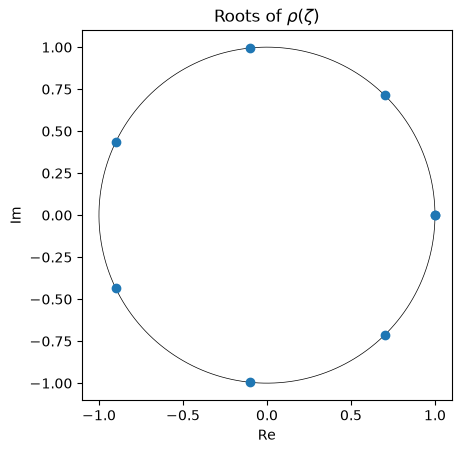

In [59]:
sstablealpha = np.array([1,-7/5,9/25,22/125,-34/125,22/125,9/25,-7/5,1])
sStableRoots = np.roots(sstablealpha)

with np.printoptions(precision=4, suppress=True):
    print("|zeta| =", np.abs(sStableRoots))
    print("zeta   =", np.round(sStableRoots, 4))

sstabletheta = np.linspace(0,2*np.pi,400)
plt.plot(np.cos(sstabletheta),np.sin(sstabletheta),"k",lw=0.5)
plt.plot(sStableRoots.real,sStableRoots.imag,"o")
plt.gca().set_aspect("equal")
plt.xlabel("Re")
plt.ylabel("Im")
plt.title(r"Roots of $\rho(\zeta)$")
plt.show()

These results are evidently show the same results as was obtained analytically. The polynomial
$$
\rho(\zeta)=a_0+a_1\zeta+a_2\zeta^2+a_3\zeta^3+a_4\zeta^4+a_5\zeta^5+a_6\zeta^6+a_7\zeta^7+a_8\zeta^8. 
$$
has $8$ roots, all with absolute value $|\zeta|=1$ (the first print-sentence). $6$ of the roots are simple and represent the roots $\zeta=e^{\pm i\theta_j},\quad \cos\theta_j\in\{0.7,\,-0.1,\,-0.9\}$. In addition, the last two roots `1. +0.j` and `1. -0.j` is the root $\zeta=1$ with multiplicity $2$.

## **Showing the conditions in the proof are actually needed:**

Recall that zero-stability is definied in the limit $h \to 0$, meaning $\sum_{i=0}^8 a_i x_{m+i} = 0$. Let us look at solutions to this recursion. 

An obvious first step would be to select the roots of $\rho$ as solutions to the recursion. Let $x_n=\zeta^n$. Then
$$\sum_{i=0}^8 a_i \zeta^{m+i} = \zeta^m \sum_{i=0}^8 a_i \zeta^{i} = \zeta^m \rho(\zeta) = 0.$$

Hence $x_n=\zeta^n$ solves the recursion for every root $\zeta$ of $\rho$. Since we have an $8$-step method, each new value $x_n$ is built from the $8$ previous values. Therefore, a solution is determined by its $8$ starting values $(x_0, \dots, x_7) \in \mathbb{R}^8$, and each choice of starting values gives exactly one solution. Since the recursion is linear, any linear combination of solutions is also a solution, so the solutions form an $8$-dimensional solution space. Spanning it requires $8$ linearly independent basis solutions. However, since we only have $7$ distinct roots of $\rho$, the solutions $\zeta^n$ cannot possibly span the entire solution space.

This is why we must find one more solution. It comes from the double root at $\zeta=1$: differentiating $\sum_{i}a_i\zeta^{m+i}=\zeta^m\rho(\zeta)$ with respect to $\zeta$ gives
$$\sum_{i=0}^8 a_i (m+i)\zeta^{m+i-1} = m\zeta^{m-1}\rho(\zeta)+\zeta^m\rho'(\zeta).$$
At $\zeta=1$ we get 
$$\sum_{i=0}^8 a_i (m+i) = m \rho(1)+\rho'(1).$$

Both $\rho(1)=0$ and $\rho'(1)=0$, so the right-hand side vanishes and $x_n=n$ is also a solution. Now we can represent all solutions as the following linear combination:
$$x_n=A\cdot1+B\cdot n+\sum_{j=1}^{3}\big(C_j\cos(n\theta_j)+D_j\sin(n\theta_j)\big).$$
Finally, notice that all terms are bounded except the term $B\cdot n$. This means that any valid solution will at most grow linearly. 

Time to show this numerically. To compute the coefficients of $\rho(\zeta)=(\zeta-1)^2\prod_{j=1}^{3}(\zeta^2+2c_j\zeta+1)$ from the constants $c_j$, we use `numpy.convolve`, which returns the discrete, linear convolution of two one-dimensional sequences. Convolving the coefficient lists of two polynomials is the same as multiplying the polynomials, so applying it to all five factors, $(\zeta-1)$ twice and the three quadratics, gives the coefficients of $\rho$.

We first use the valid constants $c=(-0.7,\ 0.1,\ 0.9)$ and then the invalid constants $c=(-0.7,\ 0.1,\ 1.1)$, where $0.9$ is replaced by $1.1>1$. The factor $\zeta^2+2.2\zeta+1$ then has the real roots $-1.1\pm\sqrt{0.21}$, one of which has modulus $\approx 1.558>1$. Because of this, we expect $x_n$ to grow much faster than linearly for invalid $c_j$.

For the sake of simplicity, we set $A = B = C_1 = C_2 = C_3 = D_1 = D_2 = D_3 = 1$ in the general solution, which gives
$$x_n = 1 + n + \sum_{j=1}^{3}\big(\cos(n\theta_j)+\sin(n\theta_j)\big), \qquad n = 0,\dots,7.$$
Both methods are started from these same eight values.


In [60]:
from functools import reduce

T = 1e3
h = 0.1
N = int(T / h) + 1

def rho(constants):
    factors = [[1, -1], [1, -1]]                    # (zeta-1)^2
    factors += [[1, 2*c, 1] for c in constants]     # zeta^2 + 2c_j*zeta + 1
    return reduce(np.convolve, factors)

def recurrence(a, starting_values):
    x_values = list(starting_values)
    while len(x_values) < N and abs(x_values[-1]) < 1e15:
        x_new = 0
        for i in range(8):
            x_new -= a[i] * x_values[-8 + i]
        x_values.append(x_new / a[8])
    return np.array(x_values)

valid_c = [-0.7, 0.1, 0.9]
invalid_c = [-0.7, 0.1, 1.1]

theta = np.arccos(-np.array(valid_c))               # cos(theta_j) = -c_j
n = np.arange(8)
starting_values = 1 + n + sum(np.cos(n*t) + np.sin(n*t) for t in theta)   # A = B = C_j = D_j = 1

x_valid = recurrence(rho(valid_c), starting_values)
x_invalid = recurrence(rho(invalid_c), starting_values)


with np.printoptions(precision=4, suppress=True):
    print(f"Modulus of roots for valid c: {np.abs(np.roots(rho(valid_c)))}")
    print(f"Modulus of roots for invalid c: {np.abs(np.roots(rho(invalid_c)))}")


Modulus of roots for valid c: [1. 1. 1. 1. 1. 1. 1. 1.]
Modulus of roots for invalid c: [1.5583 0.6417 1.     1.     1.     1.     1.     1.    ]


Indeed, for the array of invalid $c_j = (-0.7, 0.1, 1.1)$, we get a root with modulus greater than one: $|\zeta_1|\approx1.5583>1$. 

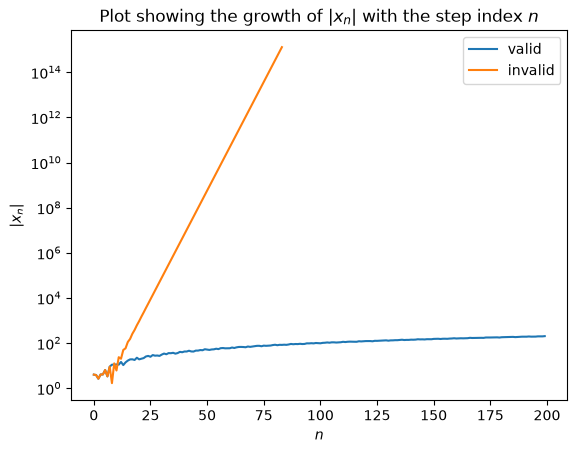

In [61]:
n_max = 200    # the invalid run reaches the 1e15 cap after about 84 steps
plt.semilogy(np.abs(x_valid[:n_max]), label="valid")
plt.semilogy(np.abs(x_invalid[:n_max]), label="invalid")
plt.xlabel(r"$n$")
plt.ylabel(r"$|x_n|$")
plt.title(r"Plot showing the growth of $|x_n|$ with the step index $n$")
plt.grid(which="minor")
plt.legend()
plt.show()

## **Conclusion**
For the valid $c_j$, $|x_n|$ grows only linearly in $n$ and is nearly flat on the logarithmic axis. For the invalid $c_j$, $|x_n|$ follows a straight line in the semilog plot, meaning it grows exponentially, at the rate $|\zeta|\approx1.558$ per step.

This shows that zero-stable methods indeed restricts the amplification/accumulation of small peturbations, and that the conditions actually matter. 

# References

[1] E. Hairer and C. Lubich, "Symmetric multistep methods for charged-particle dynamics," SMAI Journal of Computational Mathematics, vol. 3, pp. 205–218, 2017. doi: 10.5802/smai-jcm.25.

[2] TMA4215 Numerical Mathematics, "Project 2: project description," Department of Mathematical Sciences, NTNU, autumn 2026.

[3] Y. He, Y. Sun, J. Liu, and H. Qin, "Volume-preserving algorithms for charged particle dynamics," Journal of Computational Physics, vol. 281, pp. 135–147, 2015. doi: 10.1016/j.jcp.2014.10.032.